# Importamos librerías

In [1]:
import tensorflow as tf
import pathlib
import os
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import keras

In [2]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D
from tensorflow.keras.layers import MaxPooling2D
from tensorflow.keras.layers import AveragePooling2D
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Flatten
from tensorflow.keras.layers import Dropout, BatchNormalization
from tensorflow.keras.initializers import HeNormal
from keras.regularizers import l1, l2

In [3]:
tf.test.is_gpu_available()

Instructions for updating:
Use `tf.config.list_physical_devices('GPU')` instead.


True

# Importamos los datos

In [4]:
path = '../../../data/clean/Campo 100 puntos'

## Datos de entrenamiento

### Datos

In [5]:
campvectrain = np.load(path + '/campvectrain.npy')
campvectrain = np.transpose(campvectrain, (0,2,3,1))

In [6]:
np.shape(campvectrain)

(7000, 100, 100, 2)

### Coeficientes

In [7]:
coefcampvectrain = np.load(path + '/coefcampvectrain.npy')

In [8]:
np.shape(coefcampvectrain)

(7000, 7)

## Datos de prueba

### Datos

In [9]:
campvectest = np.load(path + '/campvectest.npy')
campvectest = np.transpose(campvectest, (0,2,3,1))

In [10]:
np.shape(campvectest)

(1000, 100, 100, 2)

### Coeficientes

In [11]:
coefcampvectest = np.load(path + '/coefcampvectest.npy')

In [12]:
np.shape(coefcampvectest)

(1000, 7)

## Datos de validación

### Datos

In [13]:
campvecval = np.load(path + '/campvecval.npy')
campvecval = np.transpose(campvecval, (0,2,3,1))

In [14]:
np.shape(campvecval)

(2000, 100, 100, 2)

### Coeficienes

In [15]:
coefcampvecval = np.load(path + '/coefcampvecval.npy')

In [16]:
np.shape(coefcampvecval)

(2000, 7)

# Unimos coeficientes con los datos

In [17]:
train_dataset = tf.data.Dataset.from_tensor_slices((campvectrain, coefcampvectrain))
test_dataset = tf.data.Dataset.from_tensor_slices((campvectest, coefcampvectest))
val_dataset = tf.data.Dataset.from_tensor_slices((campvecval, coefcampvecval))

In [18]:
train_dataset

<TensorSliceDataset element_spec=(TensorSpec(shape=(100, 100, 2), dtype=tf.float64, name=None), TensorSpec(shape=(7,), dtype=tf.int32, name=None))>

# Mezclar y procesar por lotes los conjuntos de datos

In [19]:
BATCH_SIZE = 100
SHUFFLE_BUFFER_SIZE = 100

train_dataset = train_dataset.shuffle(SHUFFLE_BUFFER_SIZE).batch(BATCH_SIZE)
test_dataset = test_dataset.batch(BATCH_SIZE)
val_dataset = val_dataset.batch(BATCH_SIZE)

# Creación del modelo

In [4]:
def custom_activation(x):
    return 10 * tf.nn.sigmoid(x)

In [5]:
def total_mae_loss(y_true, y_pred):
    total_loss = 0
    num_parameters = 7
    for i in range(num_parameters):
        total_loss += tf.keras.losses.mean_absolute_error(y_true[:, i], y_pred[:, i])
    tf.print(y_true, summarize = -1)
    tf.print(y_pred, summarize = -1)
    return total_loss / num_parameters

In [6]:
coeficientesnombres = ('a_1', 'a_2', 'b_1', 'b_2', 'd_1', 'd_2', 'n')

def mse_component(i):
    def mse_i(y_true, y_pred):
        return tf.keras.losses.mean_absolute_error(y_true[:, i], y_pred[:, i])

    mse_i.__name__ = coeficientesnombres[i]
    return mse_i

def mean_metric(y_true, y_pred):
    total_loss = 0
    for i in range(7):
        total_loss += mse_component(i)(y_true, y_pred)
    sum_of_true_coefficients = tf.reduce_sum(y_true, axis=-1)
    return total_loss / sum_of_true_coefficients

metrics = [mse_component(i) for i in range(7)] + [mean_metric]

In [7]:
def scheduler(epoch, lr):
  if epoch < 400:
    return lr
  else:
    return -1.65e-6*epoch +  0.00166

In [ ]:
import optuna
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam, RMSprop, SGD
from tensorflow.keras.regularizers import l1, l2

early_stop = tf.keras.callbacks.EarlyStopping( monitor = 'val_loss', patience = 1000,verbose = 1, 
                                              restore_best_weights = True)

reduce_lr = tf.keras.callbacks.LearningRateScheduler(scheduler)

def objective(trial):
    model = Sequential()
    n_conv_layers = trial.suggest_int("n_conv_layers", 1, 3)
    
    input_shape = (100, 100, 2)  # Tus dimensiones de entrada
    current_shape = input_shape
    
    for i in range(n_conv_layers):
        num_filters = trial.suggest_int(f"num_filters_{i+1}", 8, 64)
        filter_size1 = trial.suggest_int(f"filter_size1_{i+1}", 2, 5)
        filter_size2 = trial.suggest_int(f"filter_size2_{i+1}", 2, 5)
        activation = trial.suggest_categorical(f"activation_{i+1}", ['relu', 'tanh', 'sigmoid'])
        kernel_initializer = trial.suggest_categorical(f"kernel_initializer_{i+1}", ['HeNormal', 'glorot_uniform', 'random_normal'])
        kernel_regularizer = trial.suggest_categorical(f"kernel_regularizer_{i+1}", ['l1', 'l2'])
        
        regularizer = None
        if kernel_regularizer == 'l1':
            regularizer = l1(0.001)
        elif kernel_regularizer == 'l2':
            regularizer = l2(0.001)
            
            
        if (current_shape[0] - filter_size1 + 1 > 0) and (current_shape[1] - filter_size2 + 1 > 0):
            if i == 0:
                model.add(Conv2D(num_filters, (filter_size1, filter_size2), activation=activation, input_shape=input_shape, kernel_initializer=kernel_initializer, kernel_regularizer=regularizer))
            else:
                model.add(Conv2D(num_filters, (filter_size1, filter_size2), activation=activation, kernel_initializer=kernel_initializer, kernel_regularizer=regularizer))
            
            current_shape = (current_shape[0] - filter_size1 + 1, current_shape[1] - filter_size2 + 1, num_filters)
            
        # Decide si agregar una capa de MaxPooling después de esta capa convolucional
        add_maxpooling = trial.suggest_categorical(f"add_maxpooling_after_conv_{i+1}", [True, False])
        if add_maxpooling:
            if current_shape[0] >= 2 and current_shape[1] >= 2:  # Asegurarse de que ambas dimensiones son suficientes para MaxPooling
                model.add(MaxPooling2D(pool_size=(2, 2)))
                current_shape = (current_shape[0] // 2, current_shape[1] // 2, current_shape[2])
        
    model.add(Flatten())
    n_dense_layers = trial.suggest_int("n_dense_layers", 1, 4)
    
    for i in range(n_dense_layers):
        num_units = trial.suggest_int(f"num_units_{i+1}", 16, 128)
        activation = trial.suggest_categorical(f"dense_activation_{i+1}", ['relu', 'tanh', 'sigmoid'])
        kernel_initializer = trial.suggest_categorical(f"dense_kernel_initializer_{i+1}", ['HeNormal', 'glorot_uniform', 'random_normal'])
        kernel_regularizer = trial.suggest_categorical(f"dense_kernel_regularizer_{i+1}", ['l1', 'l2'])

        regularizer = None
        if kernel_regularizer == 'l1':
            regularizer = l1(0.001)
        elif kernel_regularizer == 'l2':
            regularizer = l2(0.001)

        model.add(Dense(num_units, activation=activation, kernel_initializer=kernel_initializer, kernel_regularizer=regularizer))
    
        # Decide si agregar una capa de Dropout después de esta capa densa
        add_dropout = trial.suggest_categorical(f"add_dropout_after_dense_{i+1}", [True, False])
        if add_dropout:
            dropout_rate = trial.suggest_float(f"dropout_rate_after_dense_{i+1}", 0.1, 0.5)
            model.add(Dropout(dropout_rate))
            
    model.add(Dense(7, activation=custom_activation))
        
    optimizer = Adam(learning_rate=0.001, clipvalue=100.0)
        
    model.compile(optimizer=optimizer, loss= 'mean_squared_error', metrics=metrics)
    
    history = model.fit(
        train_dataset, 
        validation_data=val_dataset, 
        epochs=20,  
        callbacks=[reduce_lr, early_stop]
    )
    
    val_mean_metric = history.history['val_mean_metric'][-1]
    
    return val_mean_metric

study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=200)

print(f'Número de trials finalizados: {len(study.trials)}')
print(f'Mejor trial:')
trial = study.best_trial

print(f'  Valor: {trial.value}')
print('  Parámetros: ')
for key, value in trial.params.items():
    print(f'    {key}: {value}')

C:\Users\rafae\anaconda3\envs\tfgpu\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2023-10-24 19:54:35,081] A new study created in memory with name: no-name-24333745-8ab8-4cca-8c63-32aac7d7a3d2


Epoch 1/20
70/70 [==============================] - 3s 30ms/step - loss: 13.8012 - a_1: 2.6046 - a_2: 2.5811 - b_1: 2.8057 - b_2: 2.7426 - d_1: 2.6823 - d_2: 2.0982 - n: 1.3532 - mean_metric: 0.5262 - val_loss: 9.9581 - val_a_1: 2.4903 - val_a_2: 2.4918 - val_b_1: 2.7459 - val_b_2: 2.6440 - val_d_1: 2.4281 - val_d_2: 1.3021 - val_n: 1.2651 - val_mean_metric: 0.4791 - lr: 0.0010
Epoch 2/20
70/70 [==============================] - 2s 25ms/step - loss: 9.9117 - a_1: 2.4821 - a_2: 2.5227 - b_1: 2.6478 - b_2: 2.6718 - d_1: 1.6958 - d_2: 1.3335 - n: 1.2568 - mean_metric: 0.4558 - val_loss: 9.4942 - val_a_1: 2.4863 - val_a_2: 2.4671 - val_b_1: 2.5091 - val_b_2: 2.6709 - val_d_1: 1.3114 - val_d_2: 1.1699 - val_n: 1.2961 - val_mean_metric: 0.4337 - lr: 0.0010
Epoch 3/20
70/70 [==============================] - 2s 25ms/step - loss: 9.5646 - a_1: 2.4681 - a_2: 2.4921 - b_1: 2.5187 - b_2: 2.6693 - d_1: 1.2844 - d_2: 1.2067 - n: 1.2569 - mean_metric: 0.4336 - val_loss: 9.8571 - val_a_1: 2.4782 - va

[I 2023-10-24 19:55:11,407] Trial 0 finished with value: 0.3463002145290375 and parameters: {'n_conv_layers': 1, 'num_filters_1': 15, 'filter_size1_1': 2, 'filter_size2_1': 3, 'activation_1': 'sigmoid', 'kernel_initializer_1': 'random_normal', 'kernel_regularizer_1': 'l1', 'add_maxpooling_after_conv_1': False, 'n_dense_layers': 4, 'num_units_1': 50, 'dense_activation_1': 'tanh', 'dense_kernel_initializer_1': 'glorot_uniform', 'dense_kernel_regularizer_1': 'l1', 'add_dropout_after_dense_1': False, 'num_units_2': 59, 'dense_activation_2': 'relu', 'dense_kernel_initializer_2': 'random_normal', 'dense_kernel_regularizer_2': 'l2', 'add_dropout_after_dense_2': False, 'num_units_3': 23, 'dense_activation_3': 'sigmoid', 'dense_kernel_initializer_3': 'random_normal', 'dense_kernel_regularizer_3': 'l2', 'add_dropout_after_dense_3': False, 'num_units_4': 61, 'dense_activation_4': 'tanh', 'dense_kernel_initializer_4': 'HeNormal', 'dense_kernel_regularizer_4': 'l2', 'add_dropout_after_dense_4': Tru

Epoch 1/20
70/70 [==============================] - 3s 39ms/step - loss: 18.6438 - a_1: 4.3040 - a_2: 2.6302 - b_1: 2.8837 - b_2: 3.6473 - d_1: 2.7215 - d_2: 4.5688 - n: 2.0020 - mean_metric: 0.7101 - val_loss: 14.4428 - val_a_1: 3.9262 - val_a_2: 2.4901 - val_b_1: 2.7522 - val_b_2: 2.8068 - val_d_1: 2.7121 - val_d_2: 3.7917 - val_n: 1.3076 - val_mean_metric: 0.6169 - lr: 0.0010
Epoch 2/20
70/70 [==============================] - 2s 32ms/step - loss: 11.3313 - a_1: 2.8990 - a_2: 2.5095 - b_1: 2.7416 - b_2: 2.7397 - d_1: 2.7112 - d_2: 2.9794 - n: 1.2074 - mean_metric: 0.5549 - val_loss: 10.0330 - val_a_1: 2.4791 - val_a_2: 2.4909 - val_b_1: 2.7517 - val_b_2: 2.7216 - val_d_1: 2.7147 - val_d_2: 2.7123 - val_n: 1.2469 - val_mean_metric: 0.5337 - lr: 0.0010
Epoch 3/20
70/70 [==============================] - 2s 32ms/step - loss: 9.8284 - a_1: 2.4860 - a_2: 2.5072 - b_1: 2.7464 - b_2: 2.7263 - d_1: 2.7043 - d_2: 2.7119 - n: 1.1984 - mean_metric: 0.5330 - val_loss: 9.6006 - val_a_1: 2.4861 -

[I 2023-10-24 19:55:56,771] Trial 1 finished with value: 0.14194057881832123 and parameters: {'n_conv_layers': 3, 'num_filters_1': 22, 'filter_size1_1': 2, 'filter_size2_1': 3, 'activation_1': 'sigmoid', 'kernel_initializer_1': 'random_normal', 'kernel_regularizer_1': 'l1', 'add_maxpooling_after_conv_1': True, 'num_filters_2': 14, 'filter_size1_2': 5, 'filter_size2_2': 5, 'activation_2': 'sigmoid', 'kernel_initializer_2': 'glorot_uniform', 'kernel_regularizer_2': 'l2', 'add_maxpooling_after_conv_2': True, 'num_filters_3': 17, 'filter_size1_3': 5, 'filter_size2_3': 5, 'activation_3': 'sigmoid', 'kernel_initializer_3': 'random_normal', 'kernel_regularizer_3': 'l2', 'add_maxpooling_after_conv_3': False, 'n_dense_layers': 1, 'num_units_1': 30, 'dense_activation_1': 'tanh', 'dense_kernel_initializer_1': 'HeNormal', 'dense_kernel_regularizer_1': 'l1', 'add_dropout_after_dense_1': False}. Best is trial 1 with value: 0.14194057881832123.


Epoch 1/20
70/70 [==============================] - 5s 65ms/step - loss: 26.3451 - a_1: 2.6063 - a_2: 2.5872 - b_1: 2.7949 - b_2: 2.7126 - d_1: 2.0161 - d_2: 1.9662 - n: 1.4187 - mean_metric: 0.5023 - val_loss: 12.9889 - val_a_1: 2.4898 - val_a_2: 2.4398 - val_b_1: 2.2353 - val_b_2: 2.0176 - val_d_1: 1.2121 - val_d_2: 1.2994 - val_n: 1.3063 - val_mean_metric: 0.4053 - lr: 0.0010
Epoch 2/20
70/70 [==============================] - 4s 62ms/step - loss: 11.6428 - a_1: 2.3976 - a_2: 2.3332 - b_1: 1.8608 - b_2: 1.7826 - d_1: 1.3910 - d_2: 1.4176 - n: 1.3283 - mean_metric: 0.3904 - val_loss: 9.2238 - val_a_1: 2.1527 - val_a_2: 1.9519 - val_b_1: 1.3768 - val_b_2: 1.2760 - val_d_1: 0.9593 - val_d_2: 0.9982 - val_n: 1.2262 - val_mean_metric: 0.3100 - lr: 0.0010
Epoch 3/20
70/70 [==============================] - 4s 62ms/step - loss: 9.8515 - a_1: 2.0575 - a_2: 1.9612 - b_1: 1.4913 - b_2: 1.4813 - d_1: 1.2452 - d_2: 1.2852 - n: 1.2533 - mean_metric: 0.3362 - val_loss: 8.3335 - val_a_1: 1.7344 - 

... (152 outputs left out)

[I 2023-10-24 21:25:19,101] Trial 78 finished with value: 0.09709092974662781 and parameters: {'n_conv_layers': 3, 'num_filters_1': 58, 'filter_size1_1': 4, 'filter_size2_1': 5, 'activation_1': 'tanh', 'kernel_initializer_1': 'random_normal', 'kernel_regularizer_1': 'l1', 'add_maxpooling_after_conv_1': True, 'num_filters_2': 22, 'filter_size1_2': 4, 'filter_size2_2': 3, 'activation_2': 'sigmoid', 'kernel_initializer_2': 'glorot_uniform', 'kernel_regularizer_2': 'l2', 'add_maxpooling_after_conv_2': True, 'num_filters_3': 58, 'filter_size1_3': 4, 'filter_size2_3': 5, 'activation_3': 'relu', 'kernel_initializer_3': 'glorot_uniform', 'kernel_regularizer_3': 'l1', 'add_maxpooling_after_conv_3': False, 'n_dense_layers': 2, 'num_units_1': 98, 'dense_activation_1': 'sigmoid', 'dense_kernel_initializer_1': 'HeNormal', 'dense_kernel_regularizer_1': 'l2', 'add_dropout_after_dense_1': False, 'num_units_2': 48, 'dense_activation_2': 'tanh', 'dense_kernel_initializer_2': 'random_normal', 'dense_kern

Epoch 1/20
70/70 [==============================] - 4s 52ms/step - loss: 6.9141 - a_1: 2.5302 - a_2: 2.4918 - b_1: 2.1581 - b_2: 2.0393 - d_1: 1.4317 - d_2: 1.3415 - n: 1.6027 - mean_metric: 0.4240 - val_loss: 4.5147 - val_a_1: 2.3293 - val_a_2: 2.1655 - val_b_1: 1.3930 - val_b_2: 1.3060 - val_d_1: 1.0049 - val_d_2: 1.0870 - val_n: 1.2467 - val_mean_metric: 0.3284 - lr: 0.0010
Epoch 2/20
70/70 [==============================] - 3s 49ms/step - loss: 4.4785 - a_1: 2.2306 - a_2: 1.9916 - b_1: 1.4358 - b_2: 1.3676 - d_1: 1.0837 - d_2: 1.1044 - n: 1.2619 - mean_metric: 0.3269 - val_loss: 3.4816 - val_a_1: 1.8938 - val_a_2: 1.7369 - val_b_1: 1.2185 - val_b_2: 1.1147 - val_d_1: 0.8932 - val_d_2: 0.9356 - val_n: 1.1513 - val_mean_metric: 0.2788 - lr: 0.0010
Epoch 3/20
70/70 [==============================] - 3s 49ms/step - loss: 3.5854 - a_1: 1.7957 - a_2: 1.6699 - b_1: 1.2478 - b_2: 1.2088 - d_1: 1.0341 - d_2: 1.0349 - n: 1.1848 - mean_metric: 0.2863 - val_loss: 2.8128 - val_a_1: 1.4511 - val

[I 2023-10-24 21:26:28,942] Trial 79 finished with value: 0.07907573133707047 and parameters: {'n_conv_layers': 3, 'num_filters_1': 54, 'filter_size1_1': 4, 'filter_size2_1': 5, 'activation_1': 'tanh', 'kernel_initializer_1': 'random_normal', 'kernel_regularizer_1': 'l1', 'add_maxpooling_after_conv_1': True, 'num_filters_2': 23, 'filter_size1_2': 5, 'filter_size2_2': 3, 'activation_2': 'sigmoid', 'kernel_initializer_2': 'glorot_uniform', 'kernel_regularizer_2': 'l2', 'add_maxpooling_after_conv_2': True, 'num_filters_3': 55, 'filter_size1_3': 4, 'filter_size2_3': 5, 'activation_3': 'relu', 'kernel_initializer_3': 'glorot_uniform', 'kernel_regularizer_3': 'l1', 'add_maxpooling_after_conv_3': False, 'n_dense_layers': 1, 'num_units_1': 92, 'dense_activation_1': 'sigmoid', 'dense_kernel_initializer_1': 'HeNormal', 'dense_kernel_regularizer_1': 'l2', 'add_dropout_after_dense_1': True, 'dropout_rate_after_dense_1': 0.2932968093222147}. Best is trial 63 with value: 0.05337722226977348.


Epoch 1/20
70/70 [==============================] - 6s 81ms/step - loss: 8.1663 - a_1: 2.5470 - a_2: 2.5535 - b_1: 2.7353 - b_2: 2.7091 - d_1: 1.7639 - d_2: 1.6531 - n: 1.3639 - mean_metric: 0.4782 - val_loss: 6.7229 - val_a_1: 2.4864 - val_a_2: 2.4825 - val_b_1: 2.6452 - val_b_2: 2.6139 - val_d_1: 0.9924 - val_d_2: 1.0358 - val_n: 1.3043 - val_mean_metric: 0.4228 - lr: 0.0010
Epoch 2/20
70/70 [==============================] - 5s 78ms/step - loss: 7.0335 - a_1: 2.5129 - a_2: 2.5274 - b_1: 2.6497 - b_2: 2.6120 - d_1: 1.2392 - d_2: 1.2174 - n: 1.3150 - mean_metric: 0.4391 - val_loss: 6.4887 - val_a_1: 2.4794 - val_a_2: 2.4761 - val_b_1: 2.6217 - val_b_2: 2.5361 - val_d_1: 1.0549 - val_d_2: 1.0439 - val_n: 1.3027 - val_mean_metric: 0.4214 - lr: 0.0010
Epoch 3/20
67/70 [===========================>..] - ETA: 0s - loss: 6.7363 - a_1: 2.5004 - a_2: 2.5234 - b_1: 2.6015 - b_2: 2.5800 - d_1: 1.1688 - d_2: 1.1888 - n: 1.2934 - mean_metric: 0.4325

In [21]:
model = Sequential()
# Primera capa convolucional
model.add(Conv2D(50, (5, 5), activation='tanh', input_shape=(100, 100, 2),kernel_initializer='glorot_uniform', kernel_regularizer=l1(0.001)))
model.add(MaxPooling2D(pool_size=(2, 2)))

# Segunda capa convolucional
model.add(Conv2D(24, (5, 5), activation='tanh',kernel_initializer='glorot_uniform', kernel_regularizer=l1(0.001) ))
model.add(MaxPooling2D(pool_size=(2, 2)))

# Tercera capa convolucional
model.add(Conv2D(11, (5, 5), activation='tanh',kernel_initializer='glorot_uniform', kernel_regularizer=l1(0.001)))
model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Conv2D(50, (5, 5), activation='tanh',kernel_initializer='glorot_uniform', kernel_regularizer=l1(0.001)))
model.add(MaxPooling2D(pool_size=(2, 2)))


model.add(Flatten())

model.add(Dense(200, activation='tanh', kernel_initializer=HeNormal(), kernel_regularizer=l1(0.001)))
model.add(Dense(100, activation='tanh', kernel_initializer=HeNormal(), kernel_regularizer=l1(0.001)))
model.add(Dense(50,activation = 'relu', kernel_initializer=HeNormal(), kernel_regularizer=l1(0.001)))
model.add(Dropout(0.3))
model.add(Dense(7, activation= custom_activation))


In [24]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.regularizers import l1, l2

# Initialize the model
model = Sequential()

# Convolutional Layer 1
model.add(Conv2D(9, (4, 5), activation='tanh', input_shape=(100, 100, 2), kernel_initializer='glorot_uniform', kernel_regularizer=l1(0.001)))
model.add(MaxPooling2D())  # Add MaxPooling after Conv 1

# Convolutional Layer 2
model.add(Conv2D(52, (4, 3), activation='relu', kernel_initializer='he_normal', kernel_regularizer=l1(0.001)))
model.add(MaxPooling2D())  # Add MaxPooling after Conv 2

# Flatten before dense layers
model.add(Flatten())

# Dense Layer 1
model.add(Dense(121, activation='sigmoid', kernel_initializer='random_normal', kernel_regularizer=l2(0.001)))
model.add(Dropout(0.176))  # Add Dropout after Dense 1

# Dense Layer 2
model.add(Dense(59, activation='relu', kernel_initializer='he_normal', kernel_regularizer=l2(0.001)))
model.add(Dense(7, activation= custom_activation))

# Show the model architecture
model.summary()


Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 97, 96, 9)         369       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 48, 48, 9)        0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 45, 46, 52)        5668      
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 22, 23, 52)       0         
 2D)                                                             
                                                                 
 flatten (Flatten)           (None, 26312)             0         
                                                                 
 dense (Dense)               (None, 121)               3

In [69]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.regularizers import l1, l2

# Initialize the model
model = Sequential()

# Convolutional Layer 1
model.add(Conv2D(18, (4, 5), activation='tanh',input_shape=(100, 100, 2), kernel_initializer='glorot_uniform', kernel_regularizer=l1(0.001)))
model.add(MaxPooling2D())  # Add MaxPooling after Conv 1

# Convolutional Layer 2
model.add(Conv2D(43, (4, 3), activation='relu', kernel_initializer='glorot_uniform', kernel_regularizer=l1(0.001)))
model.add(MaxPooling2D())  # Add MaxPooling after Conv 2

# Flatten before dense layers
model.add(Flatten())

# Dense Layer 1
model.add(Dense(125, activation='sigmoid', kernel_initializer='random_normal', kernel_regularizer=l2(0.001)))
model.add(Dropout(0.165))  # Add Dropout after Dense 1

# Dense Layer 2
model.add(Dense(53, activation='tanh', kernel_initializer='he_normal', kernel_regularizer=l2(0.001)))
model.add(Dense(7, activation= custom_activation))

# Show the model architecture
model.summary()

Model: "sequential_8"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_12 (Conv2D)          (None, 97, 96, 18)        738       
                                                                 
 max_pooling2d_12 (MaxPoolin  (None, 48, 48, 18)       0         
 g2D)                                                            
                                                                 
 conv2d_13 (Conv2D)          (None, 45, 46, 43)        9331      
                                                                 
 max_pooling2d_13 (MaxPoolin  (None, 22, 23, 43)       0         
 g2D)                                                            
                                                                 
 flatten_8 (Flatten)         (None, 21758)             0         
                                                                 
 dense_28 (Dense)            (None, 125)              

In [10]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l1, l2

# Inicializar el modelo
model = Sequential()

# Primera capa convolucional
model.add(Conv2D(58, (4, 1), activation='relu', input_shape=(100, 100, 2), kernel_initializer='random_normal', kernel_regularizer=l1(0.001)))
model.add(MaxPooling2D(pool_size=(2, 2)))

# Aplanar
model.add(Flatten())

# Primera capa densa
model.add(Dense(28, activation='relu', kernel_initializer='HeNormal', kernel_regularizer=l1(0.001)))

# Segunda capa densa
model.add(Dense(41, activation='relu', kernel_initializer='HeNormal', kernel_regularizer=l1(0.001)))

# Tercera capa densa
model.add(Dense(120, activation='relu', kernel_initializer='HeNormal', kernel_regularizer=l1(0.001)))

# Dropout
model.add(Dropout(0.3))

# Capa de salida (Asumiendo que custom_activation es 'relu' o alguna otra función de activación que ya tienes)
model.add(Dense(7, activation=custom_activation))

# Compilar el modelo
# Aquí deberás usar el optimizador y la tasa de aprendizaje que mejor funcionen para tu caso, asumiendo que ya los tienes.
model.compile(optimizer=optimizer, loss='mean_squared_error', metrics=['mean_metric'])  # Asumiendo que mean_metric es una métrica que ya tienes

# Resumen del modelo para verificar la arquitectura
model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_1 (Conv2D)           (None, 97, 100, 58)       522       
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 48, 50, 58)       0         
 2D)                                                             
                                                                 
 flatten_1 (Flatten)         (None, 139200)            0         
                                                                 
 dense_4 (Dense)             (None, 28)                3897628   
                                                                 
 dense_5 (Dense)             (None, 41)                1189      
                                                                 
 dense_6 (Dense)             (None, 120)               5040      
                                                      

In [31]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dense, Flatten, Dropout
from tensorflow.keras.regularizers import l1, l2

# Inicializar el modelo
model = Sequential()

# Primera capa convolucional
model.add(Conv2D(56, (4, 5), activation='tanh',input_shape=(100, 100, 2), kernel_initializer='random_normal', kernel_regularizer=l1()))
model.add(MaxPooling2D())  # MaxPooling

# Segunda capa convolucional
model.add(Conv2D(21, (4, 3), activation='relu', kernel_initializer='random_normal', kernel_regularizer=l2()))
model.add(MaxPooling2D())  # MaxPooling

# Tercera capa convolucional
model.add(Conv2D(60, (4, 5), activation='relu', kernel_initializer='glorot_uniform', kernel_regularizer=l1()))

# Aplanar para capas densas
model.add(Flatten())

# Capa densa
model.add(Dense(110, activation='sigmoid', kernel_initializer='HeNormal', kernel_regularizer=l2()))

model.add(Dense(110, activation='sigmoid', kernel_initializer='HeNormal', kernel_regularizer=l2()))


model.add(Dense(7, activation=custom_activation))


# Resumen del modelo
model.summary()


Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_3 (Conv2D)           (None, 97, 96, 56)        2296      
                                                                 
 max_pooling2d_2 (MaxPooling  (None, 48, 48, 56)       0         
 2D)                                                             
                                                                 
 conv2d_4 (Conv2D)           (None, 45, 46, 21)        14133     
                                                                 
 max_pooling2d_3 (MaxPooling  (None, 22, 23, 21)       0         
 2D)                                                             
                                                                 
 conv2d_5 (Conv2D)           (None, 19, 19, 60)        25260     
                                                                 
 flatten_1 (Flatten)         (None, 21660)            

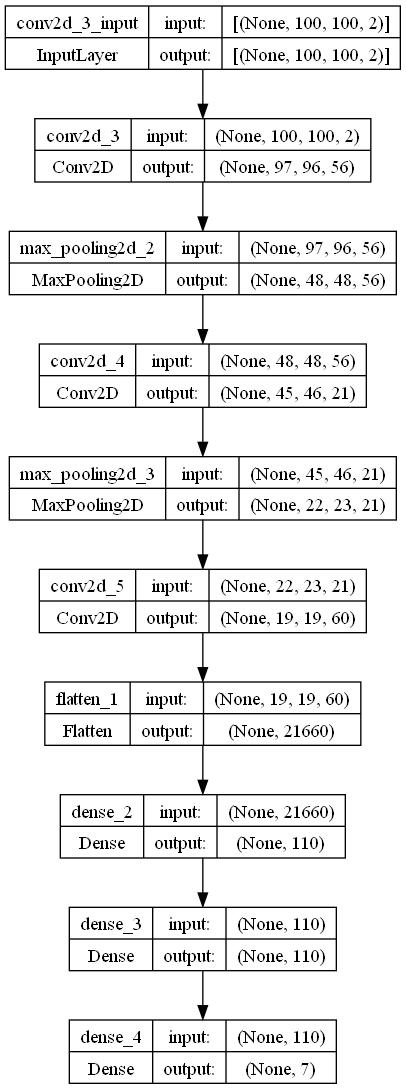

In [32]:
keras.utils.plot_model(model,show_shapes=True)

# Entrenamos el modelo

In [9]:
from keras.optimizers import Adam
optimizer = Adam(learning_rate=0.001,clipvalue=100.0)

In [12]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.regularizers import l1, l2

# Iniciar el modelo
model = Sequential()

# Input shape (Asumo que es el mismo que antes: (50, 10, 2))

# Primera capa convolucional
model.add(Conv2D(16, (4, 5), activation='relu', input_shape=(100, 100, 2), kernel_initializer='random_normal', kernel_regularizer=l2(0.001)))

# Segunda capa convolucional
model.add(Conv2D(42, (2, 4), activation='tanh', kernel_initializer='random_normal', kernel_regularizer=l2(0.001)))
model.add(MaxPooling2D(pool_size=(2, 2)))  # Añadir MaxPooling de tamaño 2x2

# Tercera capa convolucional
model.add(Conv2D(51, (3, 4), activation='tanh', kernel_initializer='HeNormal', kernel_regularizer=l2(0.001)))
model.add(MaxPooling2D(pool_size=(2, 2)))  # Añadir MaxPooling de tamaño 2x2

# Aplanar para capas densas
model.add(Flatten())

# Primera capa densa
model.add(Dense(108, activation='tanh', kernel_initializer='HeNormal', kernel_regularizer=l2(0.001)))

# Segunda capa densa
model.add(Dense(105, activation='relu', kernel_initializer='glorot_uniform', kernel_regularizer=l1(0.001)))


model.add(Dense(7, activation=custom_activation))

# Resumen del modelo para verificar la arquitectura
model.summary()

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_2 (Conv2D)           (None, 97, 96, 16)        656       
                                                                 
 conv2d_3 (Conv2D)           (None, 96, 93, 42)        5418      
                                                                 
 max_pooling2d_2 (MaxPooling  (None, 48, 46, 42)       0         
 2D)                                                             
                                                                 
 conv2d_4 (Conv2D)           (None, 46, 43, 51)        25755     
                                                                 
 max_pooling2d_3 (MaxPooling  (None, 23, 21, 51)       0         
 2D)                                                             
                                                                 
 flatten_2 (Flatten)         (None, 24633)            

In [31]:
coeficientesnombres = ('a_1', 'a_2', 'b_1', 'b_2', 'd_1', 'd_2', 'n')

def mse_component(i):
    def mse_i(y_true, y_pred):
        return tf.keras.losses.mean_absolute_error(y_true[:, i], y_pred[:, i])

    mse_i.__name__ = coeficientesnombres[i]
    return mse_i

def mean_metric(y_true, y_pred):
    total_loss = 0
    for i in range(7):
        total_loss += mse_component(i)(y_true, y_pred)
    sum_of_true_coefficients = tf.reduce_sum(y_true, axis=-1)
    return total_loss / sum_of_true_coefficients

metrics = [mse_component(i) for i in range(7)] + [mean_metric]

In [32]:
model.compile(optimizer=optimizer,
              loss= 'mean_squared_error',
              metrics=metrics)

In [33]:
def scheduler(epoch, lr):
  if epoch < 400:
    return lr
  else:
    return -1.65e-6*epoch +  0.00166
def adaptive_learning_rate(epoch):
    initial_lr = 0.001
    final_lr = 0.00001  # Updated final learning rate
    start_decay_epoch = 100
    end_decay_epoch = 1000
    
    if epoch < start_decay_epoch:
        return initial_lr
    elif epoch >= start_decay_epoch and epoch <= end_decay_epoch:
        lr_range = initial_lr - final_lr
        decay_epochs = end_decay_epoch - start_decay_epoch
        decay_per_epoch = lr_range / decay_epochs
        return initial_lr - (epoch - start_decay_epoch) * decay_per_epoch
    else:
        return final_lr

In [34]:
val_epochs = 1000

early_stop = tf.keras.callbacks.EarlyStopping( monitor = 'val_loss', patience = 100,verbose = 1, 
                                              restore_best_weights = True)

reduce_lr = tf.keras.callbacks.LearningRateScheduler(adaptive_learning_rate)
history = model.fit(train_dataset, validation_data=val_dataset, epochs= val_epochs, callbacks=[reduce_lr, early_stop])

Epoch 1/1000
70/70 [==============================] - 5s 61ms/step - loss: 7.6072 - a_1: 2.5616 - a_2: 2.5392 - b_1: 2.5902 - b_2: 2.4956 - d_1: 1.3198 - d_2: 1.3621 - n: 1.2864 - mean_metric: 0.4416 - val_loss: 6.7775 - val_a_1: 2.4963 - val_a_2: 2.5303 - val_b_1: 2.4024 - val_b_2: 2.1192 - val_d_1: 1.1865 - val_d_2: 1.1702 - val_n: 1.2885 - val_mean_metric: 0.4114 - lr: 0.0010
Epoch 2/1000
70/70 [==============================] - 4s 57ms/step - loss: 5.8407 - a_1: 2.4711 - a_2: 2.4864 - b_1: 1.9302 - b_2: 1.6038 - d_1: 1.1382 - d_2: 0.9414 - n: 1.2492 - mean_metric: 0.3688 - val_loss: 5.1702 - val_a_1: 2.4900 - val_a_2: 2.4384 - val_b_1: 1.4089 - val_b_2: 1.3788 - val_d_1: 0.9492 - val_d_2: 0.8232 - val_n: 1.2759 - val_mean_metric: 0.3356 - lr: 0.0010
Epoch 3/1000
70/70 [==============================] - 4s 57ms/step - loss: 4.9835 - a_1: 2.4428 - a_2: 2.4737 - b_1: 1.2847 - b_2: 1.2769 - d_1: 0.8246 - d_2: 0.8311 - n: 1.2498 - mean_metric: 0.3240 - val_loss: 4.8604 - val_a_1: 2.4629

70/70 [==============================] - 4s 58ms/step - loss: 0.4148 - a_1: 0.2563 - a_2: 0.2264 - b_1: 0.2851 - b_2: 0.3062 - d_1: 0.2195 - d_2: 0.2071 - n: 0.1414 - mean_metric: 0.0512 - val_loss: 0.3992 - val_a_1: 0.3418 - val_a_2: 0.2112 - val_b_1: 0.2666 - val_b_2: 0.2352 - val_d_1: 0.1755 - val_d_2: 0.1717 - val_n: 0.1190 - val_mean_metric: 0.0474 - lr: 0.0010
Epoch 44/1000
70/70 [==============================] - 4s 58ms/step - loss: 0.3834 - a_1: 0.2311 - a_2: 0.2079 - b_1: 0.2417 - b_2: 0.2376 - d_1: 0.1950 - d_2: 0.1876 - n: 0.1205 - mean_metric: 0.0444 - val_loss: 0.3993 - val_a_1: 0.3115 - val_a_2: 0.2219 - val_b_1: 0.3230 - val_b_2: 0.2480 - val_d_1: 0.1675 - val_d_2: 0.2605 - val_n: 0.1493 - val_mean_metric: 0.0524 - lr: 0.0010
Epoch 45/1000
70/70 [==============================] - 4s 58ms/step - loss: 0.4004 - a_1: 0.3077 - a_2: 0.2593 - b_1: 0.2758 - b_2: 0.2716 - d_1: 0.2162 - d_2: 0.2112 - n: 0.1368 - mean_metric: 0.0524 - val_loss: 0.3697 - val_a_1: 0.2701 - val_a_2:

70/70 [==============================] - 4s 58ms/step - loss: 0.2006 - a_1: 0.2009 - a_2: 0.1922 - b_1: 0.2080 - b_2: 0.2159 - d_1: 0.1723 - d_2: 0.1691 - n: 0.0881 - mean_metric: 0.0389 - val_loss: 0.1928 - val_a_1: 0.2279 - val_a_2: 0.1742 - val_b_1: 0.1799 - val_b_2: 0.1845 - val_d_1: 0.1592 - val_d_2: 0.1425 - val_n: 0.0817 - val_mean_metric: 0.0358 - lr: 0.0010
Epoch 86/1000
70/70 [==============================] - 4s 58ms/step - loss: 0.1990 - a_1: 0.2021 - a_2: 0.1985 - b_1: 0.2099 - b_2: 0.2136 - d_1: 0.1715 - d_2: 0.1737 - n: 0.0969 - mean_metric: 0.0395 - val_loss: 0.1998 - val_a_1: 0.1763 - val_a_2: 0.2157 - val_b_1: 0.1646 - val_b_2: 0.2977 - val_d_1: 0.1737 - val_d_2: 0.1680 - val_n: 0.0955 - val_mean_metric: 0.0403 - lr: 0.0010
Epoch 87/1000
70/70 [==============================] - 4s 58ms/step - loss: 0.2092 - a_1: 0.2320 - a_2: 0.2426 - b_1: 0.2209 - b_2: 0.2333 - d_1: 0.1789 - d_2: 0.1720 - n: 0.1077 - mean_metric: 0.0433 - val_loss: 0.2348 - val_a_1: 0.2974 - val_a_2:

70/70 [==============================] - 4s 58ms/step - loss: 0.2378 - a_1: 0.2301 - a_2: 0.2798 - b_1: 0.3078 - b_2: 0.3095 - d_1: 0.2069 - d_2: 0.2084 - n: 0.1126 - mean_metric: 0.0516 - val_loss: 0.2431 - val_a_1: 0.2528 - val_a_2: 0.2672 - val_b_1: 0.3177 - val_b_2: 0.2530 - val_d_1: 0.2717 - val_d_2: 0.2749 - val_n: 0.1053 - val_mean_metric: 0.0543 - lr: 9.7140e-04
Epoch 128/1000
70/70 [==============================] - 4s 58ms/step - loss: 0.2368 - a_1: 0.2771 - a_2: 0.2566 - b_1: 0.3054 - b_2: 0.2783 - d_1: 0.2172 - d_2: 0.2262 - n: 0.1186 - mean_metric: 0.0524 - val_loss: 0.2221 - val_a_1: 0.2574 - val_a_2: 0.2414 - val_b_1: 0.2642 - val_b_2: 0.3137 - val_d_1: 0.2068 - val_d_2: 0.1978 - val_n: 0.1064 - val_mean_metric: 0.0495 - lr: 9.7030e-04
Epoch 129/1000
70/70 [==============================] - 4s 58ms/step - loss: 0.2229 - a_1: 0.2587 - a_2: 0.2617 - b_1: 0.2539 - b_2: 0.2894 - d_1: 0.1909 - d_2: 0.1977 - n: 0.1149 - mean_metric: 0.0489 - val_loss: 0.2301 - val_a_1: 0.2494 

70/70 [==============================] - 4s 57ms/step - loss: 0.1616 - a_1: 0.2413 - a_2: 0.2236 - b_1: 0.2408 - b_2: 0.2515 - d_1: 0.1864 - d_2: 0.1850 - n: 0.0740 - mean_metric: 0.0438 - val_loss: 0.1638 - val_a_1: 0.2145 - val_a_2: 0.2262 - val_b_1: 0.2729 - val_b_2: 0.2249 - val_d_1: 0.1942 - val_d_2: 0.2267 - val_n: 0.0707 - val_mean_metric: 0.0446 - lr: 9.2520e-04
Epoch 170/1000
70/70 [==============================] - 4s 58ms/step - loss: 0.1550 - a_1: 0.2255 - a_2: 0.2118 - b_1: 0.2373 - b_2: 0.2343 - d_1: 0.1757 - d_2: 0.1821 - n: 0.0733 - mean_metric: 0.0418 - val_loss: 0.1373 - val_a_1: 0.1886 - val_a_2: 0.1515 - val_b_1: 0.1904 - val_b_2: 0.2146 - val_d_1: 0.1611 - val_d_2: 0.1787 - val_n: 0.0590 - val_mean_metric: 0.0357 - lr: 9.2410e-04
Epoch 171/1000
70/70 [==============================] - 4s 61ms/step - loss: 0.1385 - a_1: 0.1976 - a_2: 0.1672 - b_1: 0.1928 - b_2: 0.2307 - d_1: 0.1621 - d_2: 0.1599 - n: 0.0647 - mean_metric: 0.0367 - val_loss: 0.1619 - val_a_1: 0.1932 

70/70 [==============================] - 4s 58ms/step - loss: 0.1062 - a_1: 0.1610 - a_2: 0.1562 - b_1: 0.1778 - b_2: 0.1816 - d_1: 0.1423 - d_2: 0.1364 - n: 0.0658 - mean_metric: 0.0318 - val_loss: 0.1026 - val_a_1: 0.1354 - val_a_2: 0.1651 - val_b_1: 0.1790 - val_b_2: 0.1824 - val_d_1: 0.1413 - val_d_2: 0.1385 - val_n: 0.0548 - val_mean_metric: 0.0311 - lr: 8.7900e-04
Epoch 212/1000
70/70 [==============================] - 4s 58ms/step - loss: 0.1018 - a_1: 0.1345 - a_2: 0.1438 - b_1: 0.1765 - b_2: 0.1784 - d_1: 0.1429 - d_2: 0.1428 - n: 0.0711 - mean_metric: 0.0309 - val_loss: 0.1086 - val_a_1: 0.1902 - val_a_2: 0.1358 - val_b_1: 0.1816 - val_b_2: 0.1900 - val_d_1: 0.2129 - val_d_2: 0.1365 - val_n: 0.0556 - val_mean_metric: 0.0344 - lr: 8.7790e-04
Epoch 213/1000
70/70 [==============================] - 4s 58ms/step - loss: 0.1286 - a_1: 0.2018 - a_2: 0.2100 - b_1: 0.2061 - b_2: 0.2599 - d_1: 0.1624 - d_2: 0.1572 - n: 0.0674 - mean_metric: 0.0395 - val_loss: 0.1369 - val_a_1: 0.2066 

... (14 outputs left out)

70/70 [==============================] - 4s 57ms/step - loss: 0.0319 - a_1: 0.0684 - a_2: 0.0573 - b_1: 0.0787 - b_2: 0.0703 - d_1: 0.0626 - d_2: 0.0518 - n: 0.0325 - mean_metric: 0.0132 - val_loss: 0.0324 - val_a_1: 0.0733 - val_a_2: 0.0585 - val_b_1: 0.0738 - val_b_2: 0.0843 - val_d_1: 0.0585 - val_d_2: 0.0496 - val_n: 0.0311 - val_mean_metric: 0.0134 - lr: 1.8600e-04
Epoch 842/1000
70/70 [==============================] - 4s 58ms/step - loss: 0.0330 - a_1: 0.0699 - a_2: 0.0746 - b_1: 0.0765 - b_2: 0.0754 - d_1: 0.0707 - d_2: 0.0541 - n: 0.0358 - mean_metric: 0.0143 - val_loss: 0.0333 - val_a_1: 0.0596 - val_a_2: 0.0677 - val_b_1: 0.0818 - val_b_2: 0.0880 - val_d_1: 0.0771 - val_d_2: 0.0556 - val_n: 0.0315 - val_mean_metric: 0.0144 - lr: 1.8490e-04
Epoch 843/1000
70/70 [==============================] - 4s 61ms/step - loss: 0.0326 - a_1: 0.0683 - a_2: 0.0583 - b_1: 0.0734 - b_2: 0.0817 - d_1: 0.0675 - d_2: 0.0598 - n: 0.0326 - mean_metric: 0.0138 - val_loss: 0.0325 - val_a_1: 0.0653 

70/70 [==============================] - 4s 58ms/step - loss: 0.0304 - a_1: 0.0588 - a_2: 0.0513 - b_1: 0.0730 - b_2: 0.0730 - d_1: 0.0586 - d_2: 0.0502 - n: 0.0294 - mean_metric: 0.0123 - val_loss: 0.0302 - val_a_1: 0.0618 - val_a_2: 0.0480 - val_b_1: 0.0738 - val_b_2: 0.0646 - val_d_1: 0.0542 - val_d_2: 0.0493 - val_n: 0.0277 - val_mean_metric: 0.0118 - lr: 1.3980e-04
Epoch 884/1000
70/70 [==============================] - 4s 58ms/step - loss: 0.0302 - a_1: 0.0572 - a_2: 0.0488 - b_1: 0.0743 - b_2: 0.0687 - d_1: 0.0612 - d_2: 0.0496 - n: 0.0308 - mean_metric: 0.0122 - val_loss: 0.0303 - val_a_1: 0.0627 - val_a_2: 0.0512 - val_b_1: 0.0750 - val_b_2: 0.0625 - val_d_1: 0.0553 - val_d_2: 0.0438 - val_n: 0.0346 - val_mean_metric: 0.0120 - lr: 1.3870e-04
Epoch 885/1000
70/70 [==============================] - 4s 58ms/step - loss: 0.0297 - a_1: 0.0576 - a_2: 0.0457 - b_1: 0.0689 - b_2: 0.0637 - d_1: 0.0572 - d_2: 0.0458 - n: 0.0308 - mean_metric: 0.0115 - val_loss: 0.0299 - val_a_1: 0.0614 

70/70 [==============================] - 4s 57ms/step - loss: 0.0290 - a_1: 0.0574 - a_2: 0.0491 - b_1: 0.0672 - b_2: 0.0654 - d_1: 0.0546 - d_2: 0.0424 - n: 0.0267 - mean_metric: 0.0113 - val_loss: 0.0294 - val_a_1: 0.0593 - val_a_2: 0.0505 - val_b_1: 0.0692 - val_b_2: 0.0654 - val_d_1: 0.0535 - val_d_2: 0.0509 - val_n: 0.0271 - val_mean_metric: 0.0117 - lr: 9.3600e-05
Epoch 926/1000
70/70 [==============================] - 4s 58ms/step - loss: 0.0287 - a_1: 0.0545 - a_2: 0.0451 - b_1: 0.0662 - b_2: 0.0611 - d_1: 0.0555 - d_2: 0.0405 - n: 0.0267 - mean_metric: 0.0109 - val_loss: 0.0295 - val_a_1: 0.0590 - val_a_2: 0.0496 - val_b_1: 0.0731 - val_b_2: 0.0666 - val_d_1: 0.0553 - val_d_2: 0.0468 - val_n: 0.0273 - val_mean_metric: 0.0118 - lr: 9.2500e-05
Epoch 927/1000
70/70 [==============================] - 4s 62ms/step - loss: 0.0287 - a_1: 0.0559 - a_2: 0.0424 - b_1: 0.0666 - b_2: 0.0613 - d_1: 0.0539 - d_2: 0.0427 - n: 0.0289 - mean_metric: 0.0110 - val_loss: 0.0292 - val_a_1: 0.0575 

70/70 [==============================] - 4s 57ms/step - loss: 0.0276 - a_1: 0.0518 - a_2: 0.0406 - b_1: 0.0620 - b_2: 0.0560 - d_1: 0.0506 - d_2: 0.0386 - n: 0.0242 - mean_metric: 0.0101 - val_loss: 0.0280 - val_a_1: 0.0518 - val_a_2: 0.0402 - val_b_1: 0.0652 - val_b_2: 0.0613 - val_d_1: 0.0527 - val_d_2: 0.0379 - val_n: 0.0237 - val_mean_metric: 0.0104 - lr: 4.7400e-05
Epoch 968/1000
70/70 [==============================] - 4s 58ms/step - loss: 0.0277 - a_1: 0.0523 - a_2: 0.0405 - b_1: 0.0614 - b_2: 0.0572 - d_1: 0.0512 - d_2: 0.0406 - n: 0.0238 - mean_metric: 0.0102 - val_loss: 0.0282 - val_a_1: 0.0555 - val_a_2: 0.0462 - val_b_1: 0.0643 - val_b_2: 0.0613 - val_d_1: 0.0502 - val_d_2: 0.0430 - val_n: 0.0247 - val_mean_metric: 0.0108 - lr: 4.6300e-05
Epoch 969/1000
70/70 [==============================] - 4s 61ms/step - loss: 0.0276 - a_1: 0.0512 - a_2: 0.0420 - b_1: 0.0615 - b_2: 0.0561 - d_1: 0.0499 - d_2: 0.0376 - n: 0.0243 - mean_metric: 0.0101 - val_loss: 0.0281 - val_a_1: 0.0584 

In [35]:
test_loss, test_a1, test_a2, test_b1, test_b2, test_d1, test_d2, test_n, testprom_per = model.evaluate(
    campvectest, coefcampvectest)

32/32 [==============================] - 0s 6ms/step - loss: 0.0274 - a_1: 0.0503 - a_2: 0.0367 - b_1: 0.0623 - b_2: 0.0581 - d_1: 0.0471 - d_2: 0.0370 - n: 0.0237 - mean_metric: 0.0098


# Analizamos accuracy y loss

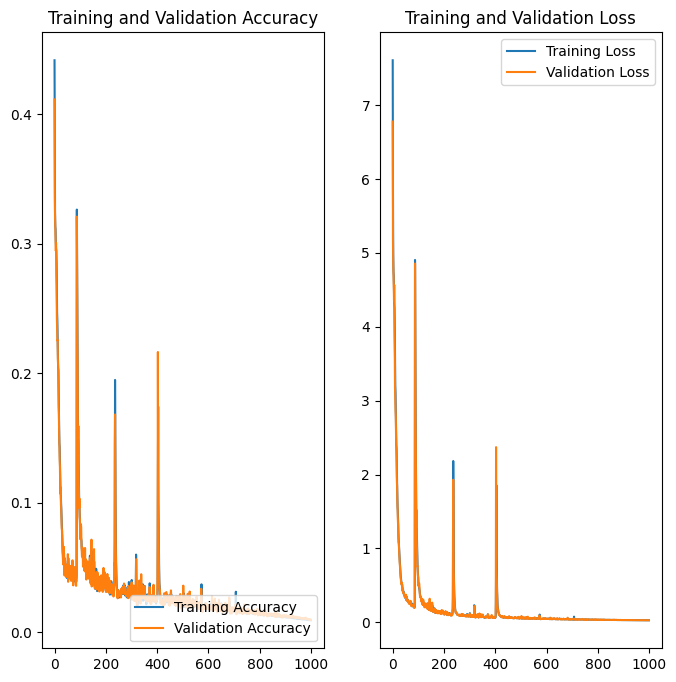

In [36]:
acc = history.history['mean_metric']
val_acc = history.history['val_mean_metric']

loss = history.history['loss']
val_loss = history.history['val_loss']

#epochs_range = range(val_epochs)
epochs_range = range(val_epochs)
plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

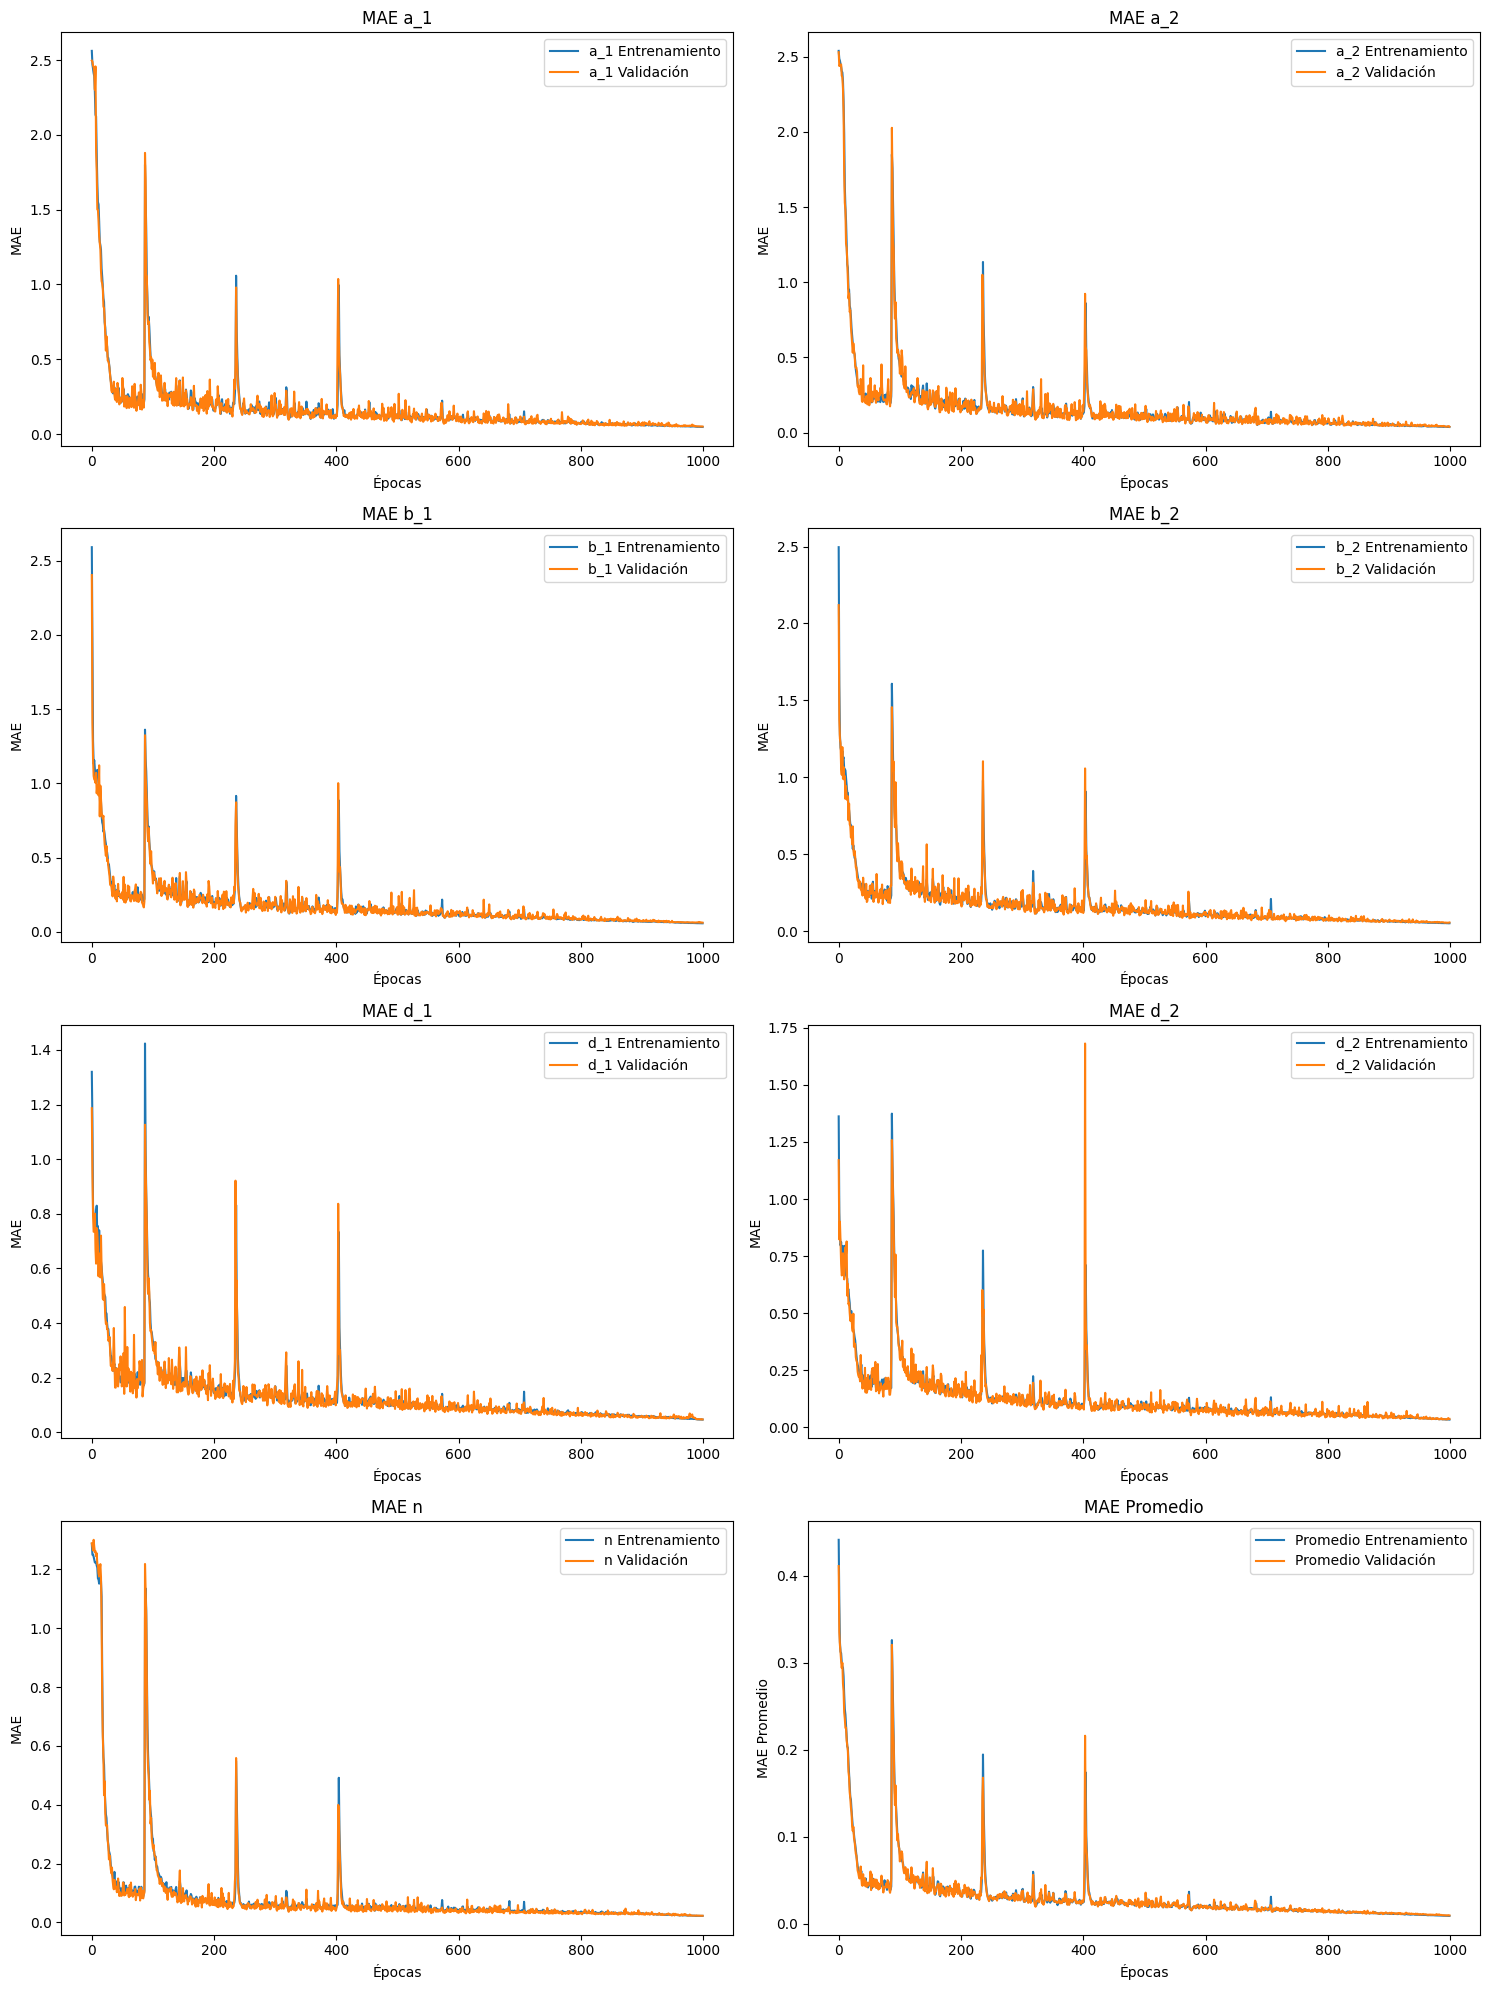

In [37]:
# Número de coeficientes más uno para la métrica adicional
n_coef = len(coeficientesnombres) + 1

# Número de filas y columnas para los subplots
n_rows = (n_coef + 1) // 2
n_cols = 2

# Crear una figura más grande para acomodar todos los subplots
plt.figure(figsize=(15, 5 * n_rows))

# Crear un subplot para cada coeficiente
for i, name in enumerate(coeficientesnombres):
    plt.subplot(n_rows, n_cols, i + 1)
    plt.plot(history.history[name ], label=name + ' Entrenamiento')
    plt.plot(history.history['val_' + name ], label=name + ' Validación')
    plt.title('MAE ' + name)
    plt.xlabel('Épocas')
    plt.ylabel('MAE')
    plt.legend()

# Agregar un subplot para la métrica prom_per
plt.subplot(n_rows, n_cols, n_coef)
plt.plot(history.history['mean_metric'], label='Promedio Entrenamiento')
plt.plot(history.history['val_mean_metric'], label='Promedio Validación')
plt.title('MAE Promedio')
plt.xlabel('Épocas')
plt.ylabel('MAE Promedio')
plt.legend()

# Ajustar el diseño para asegurarse de que todo encaje bien
plt.tight_layout()
plt.show()

# Evaluamos el modelo

In [38]:
test_loss, test_a1, test_a2, test_b1, test_b2, test_d1, test_d2, test_n, testprom_per = model.evaluate(
    campvectest, coefcampvectest)

32/32 [==============================] - 0s 6ms/step - loss: 0.0274 - a_1: 0.0503 - a_2: 0.0367 - b_1: 0.0623 - b_2: 0.0581 - d_1: 0.0471 - d_2: 0.0370 - n: 0.0237 - mean_metric: 0.0098


In [39]:
predictions = model.predict(campvectest)

32/32 [==============================] - 0s 5ms/step


In [40]:
print(coefcampvectest[0,:])
print(predictions[0,:])
from sklearn.metrics import mean_absolute_error
print(np.sum(coefcampvectest, axis=-1))

mae1 = mean_absolute_error(coefcampvectest[0,:], predictions[0,:])
mae1

[1 2 9 6 0 2 5]
[0.9687351  1.9903923  9.066783   5.9826097  0.05504237 2.0445492
 4.9843173 ]
[25 52 33 47 31 39 39 43 30 28 43 39 46 26 39 34 27 33 30 42 36 35 36 32
 42 30 29 33 31 30 17 38 36 24 38 17 33 50 31 44 13 48 38 22 46 28 25 48
 32 29 36 49 31 38 32 32 32 30 42 40 34 41 33 26 39 24 42 29 33 33 22 27
 30 18 33 36 40 27 22 20 47 30 47 32 39 38 41 27 31 35 28 43 46 49 48 45
 31 25 39 41 31 45 43 25 33 39 18 37 14 29 34 41 27 36 34 34 32 35 45 22
 45 40 48 41 35 36 42 38 20 46 35 29 25 25 54 25 39 24 41 25 31 23 37 35
 35 37 26 39 36 35 28 40 39 29 40 31 32 10 43 49 36 35 36 42 34 18 47 44
 23 43 30 30 22 39 35 34 28 37 21 41 31 31 32 40 33 44 32 31 19 41 35 49
 33 22 35 33 40 30 32 32 36 30 42 23 30 27 32 25 38 44 35 33 24 42 28 34
 26 32 29 30 40 34 33 32 45 27 19 33 31 48 26 41 46 42 30 35 38 40 39 43
 30 42 41 31 29 40 30 47 36 31 37 41 34 38 28 44 37 43 44 34 26 39 28 33
 27 18 34 37 26 46 35 40 43 46 30 39 43 13 32 40 33 41 28 20 43 41 35 32
 22 34 27 31 37 40 35 40 39 3

0.03433143932904516

In [41]:
from sklearn.metrics import mean_absolute_error
import numpy as np

# Calcula el MAE
mae = mean_absolute_error(coefcampvectest, predictions)

# Calcula la desviación estándar del error
error = coefcampvectest - predictions
std_dev = np.std(error)

# Calcula el error absoluto máximo
max_error = np.max(np.abs(error))

print(f"MAE: {mae}, Desviación estándar del error: {std_dev}, Error absoluto máximo: {max_error}")

MAE: 0.045030817969036956, Desviación estándar del error: 0.06480193620702052, Error absoluto máximo: 0.5547926425933838


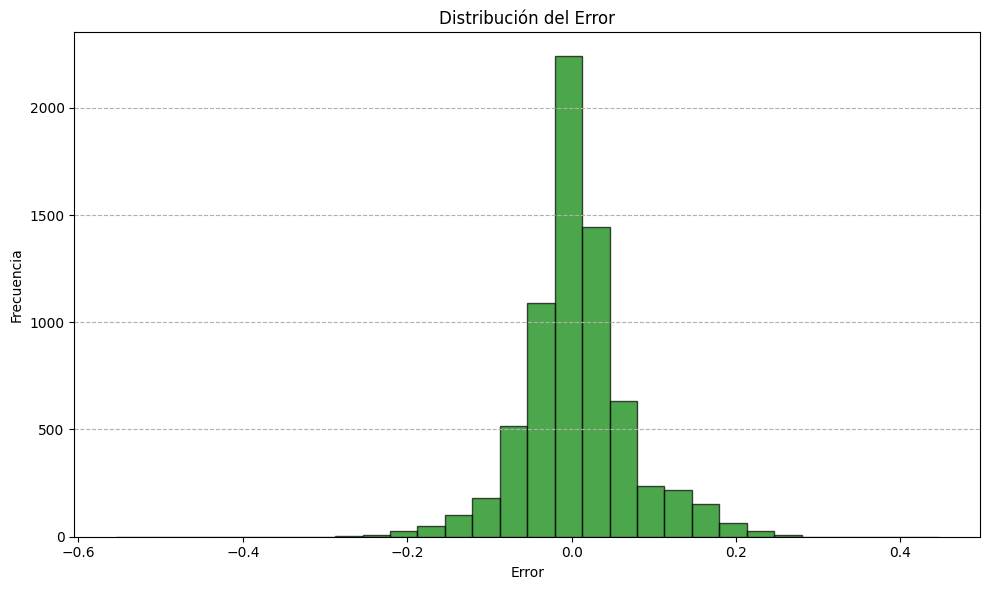

In [42]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))  # Establece el tamaño del gráfico
plt.hist(error.flatten(), bins=30, edgecolor='black', alpha=0.7, color = 'green')  # Añade bordes negros a las barras y ajusta la transparencia
plt.title('Distribución del Error')  # Añade un título al gráfico
plt.xlabel('Error')  # Etiqueta el eje x
plt.ylabel('Frecuencia')  # Etiqueta el eje y
plt.grid(axis='y', linestyle='--')  # Añade una cuadrícula horizontal
plt.tight_layout()  # Ajusta el diseño para evitar que se recorten las etiquetas
plt.show()

In [43]:
# Calcula el error absoluto para cada dato
absolute_error = np.abs(coefcampvectest - predictions)

# Calcula el error para cada dato
error = coefcampvectest - predictions

# Calcula la suma de los valores reales para cada dato
sum_real_values = np.sum(coefcampvectest, axis=-1)

# Divide el error absoluto por la suma de los valores reales para cada dato
relative_error_per_data = np.sum(absolute_error, axis=-1) / sum_real_values

# Calcula el MAE relativo como la media de los errores relativos
relative_mae = np.mean(relative_error_per_data)

# Divide el error por la suma de los valores reales para cada dato
relative_error_per_data_std_max = np.sum(error, axis=-1) / sum_real_values

# Calcula la desviación estándar del error relativo
relative_std_dev = np.std(relative_error_per_data_std_max)

# Calcula el error absoluto máximo relativo
relative_max_error = np.max(np.abs(relative_error_per_data_std_max))

print(f"MAE relativo: {relative_mae}")
print(f"Desviación estándar del error relativo: {relative_std_dev}")
print(f"Error absoluto máximo relativo: {relative_max_error}")


MAE relativo: 0.009993653412321293
Desviación estándar del error relativo: 0.005971692124044232
Error absoluto máximo relativo: 0.0606346892622801


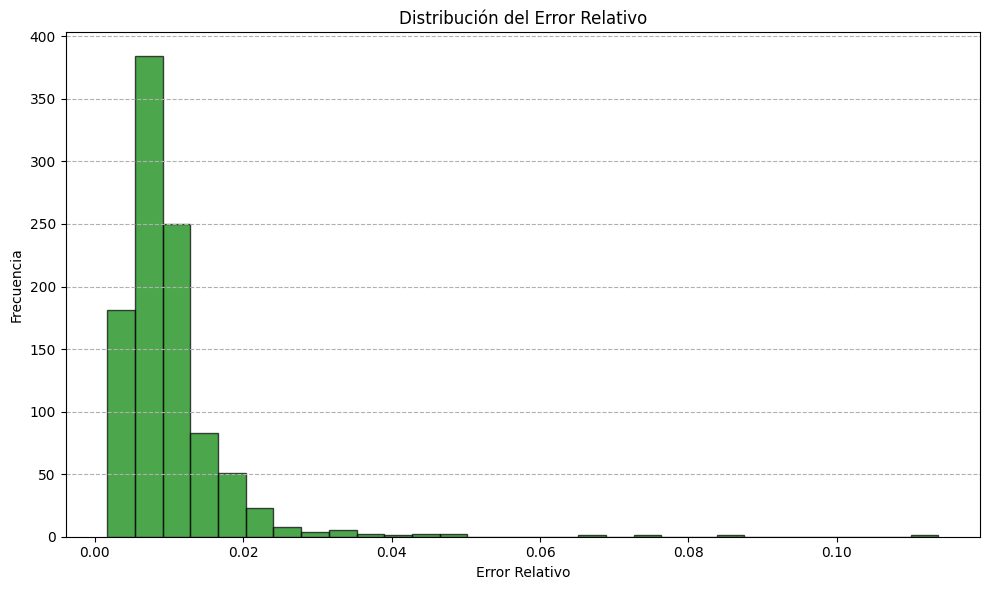

In [44]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))  # Establece el tamaño del gráfico
plt.hist(relative_error_per_data, bins=30, edgecolor='black', alpha=0.7, color = 'green')  # Añade bordes negros a las barras y ajusta la transparencia
plt.title('Distribución del Error Relativo')  # Añade un título al gráfico
plt.xlabel('Error Relativo')  # Etiqueta el eje x
plt.ylabel('Frecuencia')      # Etiqueta el eje y
plt.grid(axis='y', linestyle='--')  # Añade una cuadrícula horizontal
plt.tight_layout()  # Ajusta el diseño para evitar que se recorten las etiquetas
plt.show()


# Guardamos los datos de Accuracy y Loss

In [45]:
df = pd.DataFrame.from_dict(history.history)
df.to_csv('../../../Gráficas finales/grid100_traj200/historyconvcampvec100.csv', index=False)

# Guardamos el modelo

In [46]:
path_to_save = '../../../trained_models_clean/grid100_traj200/'

In [47]:
model.save(path_to_save + '/convolucionalcv100.h5')

# Importamos el modelo

In [1]:
def custom_activation(x):
    return 10 * tf.nn.sigmoid(x)

In [2]:
coeficientesnombres = ('a_1', 'a_2', 'b_1', 'b_2', 'd_1', 'd_2', 'n')

def mse_component(i):
    def mse_i(y_true, y_pred):
        return tf.keras.losses.mean_absolute_error(y_true[:, i], y_pred[:, i])

    mse_i.__name__ = coeficientesnombres[i]
    return mse_i

def mean_metric(y_true, y_pred):
    total_loss = 0
    for i in range(7):
        total_loss += mse_component(i)(y_true, y_pred)
    sum_of_true_coefficients = tf.reduce_sum(y_true, axis=-1)
    return total_loss / sum_of_true_coefficients

metrics = [mse_component(i) for i in range(7)] + [mean_metric]

In [3]:
import keras
import tensorflow as tf
# Creación de un diccionario con todas las métricas personalizadas
custom_objects = {'custom_activation':custom_activation,'mean_metric': mean_metric}
for i in range(7):
    custom_objects[coeficientesnombres[i]] = mse_component(i)
new_model = keras.models.load_model('../../../trained_models_clean/grid100_traj200/convolucionalcv100.h5', custom_objects=custom_objects)

In [17]:
new_model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_3 (Conv2D)           (None, 97, 96, 16)        656       
                                                                 
 conv2d_4 (Conv2D)           (None, 96, 93, 42)        5418      
                                                                 
 max_pooling2d_2 (MaxPooling  (None, 48, 46, 42)       0         
 2D)                                                             
                                                                 
 conv2d_5 (Conv2D)           (None, 46, 43, 51)        25755     
                                                                 
 max_pooling2d_3 (MaxPooling  (None, 23, 21, 51)       0         
 2D)                                                             
                                                                 
 flatten_1 (Flatten)         (None, 24633)            

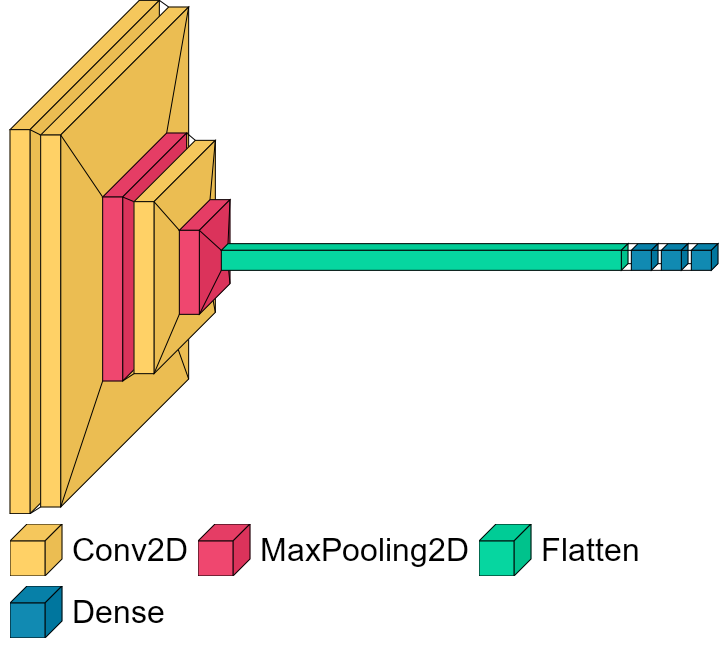

In [7]:
import visualkeras
from PIL import ImageFont

font = ImageFont.truetype("arial.ttf", 32)  # using comic sans is strictly prohibited!
visualkeras.layered_view(new_model, legend=True, font=font)  # font is optional!

  Using cached ann_visualizer-2.5.tar.gz (4.7 kB)
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
  Created wheel for ann_visualizer: filename=ann_visualizer-2.5-py3-none-any.whl size=4168 sha256=57895b2bf6cf57ff66b756583f73a690ba2383240007def637e45b27f71a887b
  Stored in directory: c:\users\rafae\appdata\local\pip\cache\wheels\2d\d8\86\67f4a249969eaaa31c6df569f4ebfa84634fae3af2c627107b
Successfully built ann_visualizer


# Probamos el modelo con datos nuevos

## Creamos nuevos datos

In [51]:
import random
from scipy.integrate import solve_ivp

campvec = []
coef = []
contador = 0
for i in range(0, 1):
    # constantes
    a1 = random.randint(0, 10)
    a2 = random.randint(0, 10)
    b1 = random.randint(0, 10)
    b2 = random.randint(0, 10)
    d1 = random.randint(0, 10)
    d2 = random.randint(0, 10)
    n = random.randint(0, 5)

    coef1 = [a1, a2, b1, b2, d1, d2, n]
    coef.append(coef1)

    def f(t, y):

        # asignar a cada ODE a un elemento de vector
        X = y[0]
        Y = y[1]

        # definimos cada ODE
        # dX_dt=a1/(1+Y**n)-d1*X+b1
        # dY_dt=a2/(1+X**n)-d2*Y+b2
        dX_dt = a1/(1+Y**n)-d1*X+b1
        dY_dt = a2/(1+X**n)-d2*Y+b2

        return [dX_dt, dY_dt]

    x_range_neg = 0
    x_range_pos = 10
    y_range_neg = 0
    y_range_pos =10

    y1 = np.linspace(x_range_neg, x_range_pos, 100)
    y2 = np.linspace(y_range_neg, y_range_pos, 100)

    Y1, Y2 = np.meshgrid(y1, y2)
    
    t1 = 0

    u, v = np.zeros(Y1.shape), np.zeros(Y2.shape)

    NI, NJ = Y1.shape

    u1, v1 = f(t1, [Y1, Y2])
    u, v = f(t1, [Y1, Y2])
    M = (np.hypot(u, v))
    u /= M
    v /= M

    campvecci = np.append([u1], [v1], axis=0)

    campvec = campvecci
    print('--------------------------------------------')
    print(coef1)

    
campvec = np.array(campvec)
coef = np.array(coef)


--------------------------------------------
[1, 9, 1, 3, 2, 10, 2]


In [52]:
campvecnone = campvec[None, :]
campvecnone = np.transpose(campvecnone, (0,2,3,1))

## Predecimos con los datos nuevos

In [53]:
new_predictions = new_model.predict(campvecnone)
new_predictions = np.round(new_predictions)
new_predictions = np.clip(new_predictions, 0, None)
print(new_predictions)

1/1 [==============================] - 0s 49ms/step
[[ 1.  9.  1.  3.  2. 10.  2.]]


## Encontramos puntos de equilibro datos reales

In [54]:
from scipy.optimize import fsolve
# Sistema de ecuaciones
def system(Y):
    X, Y = Y
    dX_dt = a1/(1+Y**n)-d1*X+b1
    dY_dt = a2/(1+X**n)-d2*Y+b1
    return [dX_dt, dY_dt]

# Adivinanza inicial para X, Y
initial_guess = [0, 0]

# Encontrar los puntos de equilibrio
primer_cuadrante_reales = fsolve(system, initial_guess)
primer_cuadrante_reales = tuple(primer_cuadrante_reales)


print(primer_cuadrante_reales)

(0.8624220411232748, 0.6161225865839054)


## Graficamos con los coeficientes reales

Text(0, 0.5, 'Concentración Y')

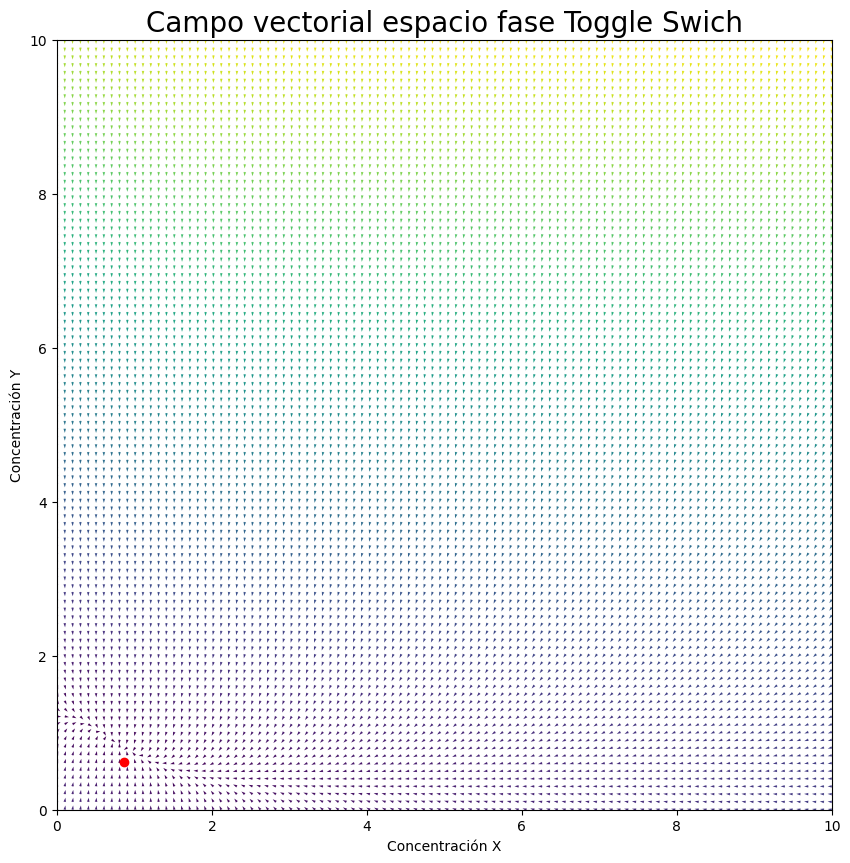

In [55]:
import matplotlib.pyplot as plt

x_values = primer_cuadrante_reales[0]
y_values =primer_cuadrante_reales[1]
y1 = np.linspace(0, 10, 100)
y2 = np.linspace(0, 10, 100)
Y1, Y2 = np.meshgrid(y1, y2)
t1 = 0
u, v = np.zeros(Y1.shape), np.zeros(Y2.shape)
NI, NJ = Y1.shape        
u,v = np.array(campvec)[0,:,:], np.array(campvec)[1,:,:]
M = (np.hypot(u,v))
u /= M
v /= M

plt.figure(figsize=(10,10))
Q = plt.quiver(Y1, Y2, u, v, M, angles='xy')
plt.title('Campo vectorial espacio fase Toggle Swich', fontsize=20)
plt.xlim([0, 10])
plt.ylim([0, 10])
plt.scatter(x_values, y_values, color='red')  # Puedes cambiar el color como prefieras
plt.xlabel('Concentración X')
plt.ylabel('Concentración Y')

## Encontramos puntos de equilibro datos predecidos

In [56]:
a1pred = new_predictions[0,0]
a2pred = new_predictions[0,1]
b1pred = new_predictions[0,2]
b2pred = new_predictions[0,3]
d1pred = new_predictions[0,4]
d2pred = new_predictions[0,5]
npred = new_predictions[0,6]

def systempred(Ypred):
    Xpred, Ypred = Ypred
    dXpred_dt = a1pred/(1+Ypred**npred)-d1pred*Xpred+b1pred
    dYpred_dt = a2pred/(1+Xpred**npred)-d2pred*Ypred+b1pred
    return [dXpred_dt, dYpred_dt]

# Adivinanza inicial para X, Y
initial_guesspred = [0, 0]

# Encontrar los puntos de equilibrio
primer_cuadrante_predecidos = fsolve(systempred, initial_guesspred)
primer_cuadrante_predecidos = tuple(primer_cuadrante_predecidos)


print(primer_cuadrante_predecidos)

(0.8624220411232748, 0.6161225865839054)


## Graficamos con los coeficientes predecidos

Text(0, 0.5, 'Concentración Y')

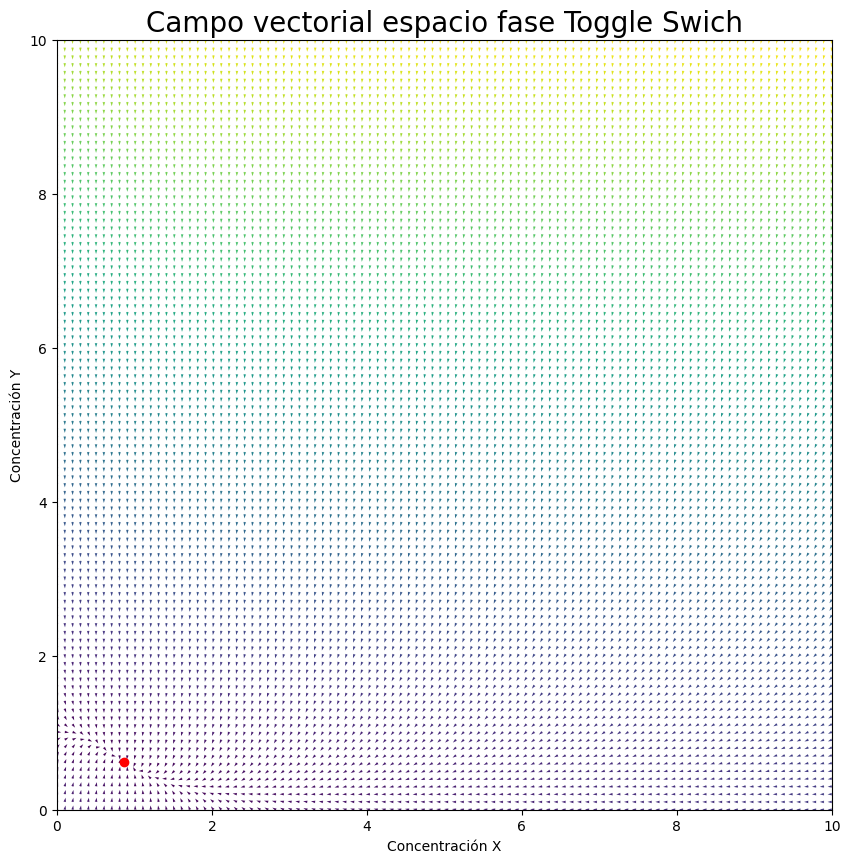

In [57]:
import matplotlib.pyplot as plt

def f(t, y):

    # asignar a cada ODE a un elemento de vector
    X = y[0]
    Y = y[1]

    # definimos cada ODE
    dX_dt = a1pred/(1+Y**npred)-d1pred*X+b1pred
    dY_dt = a2pred/(1+X**npred)-d2pred*Y+b1pred

    return [dX_dt, dY_dt]

x_range_neg = 0
x_range_pos = 10
y_range_neg = 0
y_range_pos = 10

y1pred = np.linspace(x_range_neg, x_range_pos, 100)
y2pred = np.linspace(y_range_neg, y_range_pos, 100)

Y1pred, Y2pred = np.meshgrid(y1pred, y2pred)
    
t1 = 0

upred, vpred = np.zeros(Y1pred.shape), np.zeros(Y2pred.shape)

NI, NJ = Y1.shape

u1pred, v1pred = f(t1, [Y1, Y2])
upred, vpred = f(t1, [Y1, Y2])
Mpred = (np.hypot(upred, vpred))
upred /= Mpred
vpred /= Mpred


x_valuespred = primer_cuadrante_predecidos[0]
y_valuespred =primer_cuadrante_predecidos[1]
plt.figure(figsize=(10, 10))
Q = plt.quiver(Y1, Y2, upred, vpred, Mpred, angles='xy')
plt.title('Campo vectorial espacio fase Toggle Swich', fontsize=20)
plt.xlim([x_range_neg, x_range_pos])
plt.ylim([y_range_neg, y_range_pos])
plt.scatter(x_valuespred, y_valuespred, color='red')  # Puedes cambiar el color como prefieras
plt.xlabel('Concentración X')
plt.ylabel('Concentración Y')

## Graficamos ambos

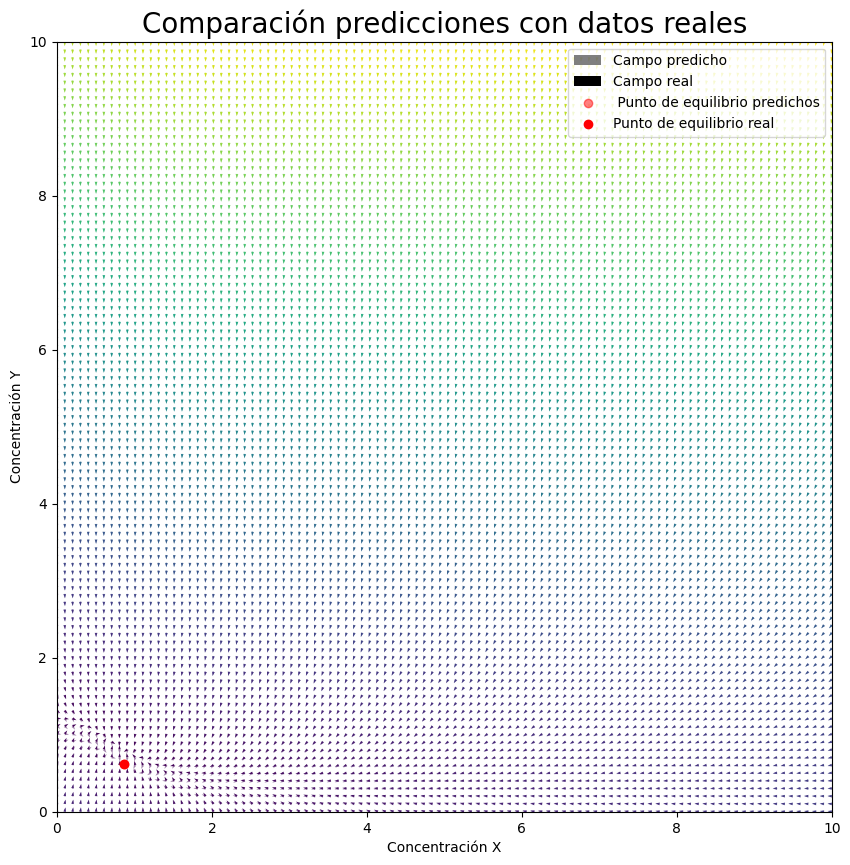

In [58]:
#%matplotlib qt
fig, ax = plt.subplots(figsize=(10, 10))

# Primero graficamos la predicción, que debería ser más clara (alpha < 1)
Q = ax.quiver(Y1, Y2, upred, vpred, Mpred, angles='xy', alpha=0.5, label = "Campo predicho")

# Luego, graficamos los datos originales, que serán más oscuros (alpha = 1)
Q1 = ax.quiver(Y1, Y2, u, v, M, angles='xy', alpha=1, label = "Campo real")

ax.scatter(x_valuespred, y_valuespred, color='red', alpha = 0.5, label = " Punto de equilibrio predichos")
ax.scatter(x_values, y_values, color='red', alpha = 1, label = "Punto de equilibrio real")
ax.set_title('Comparación predicciones con datos reales', fontsize=20)
ax.set_xlim([0, 10])
ax.set_ylim([0, 10])
ax.set_xlabel('Concentración X')
ax.set_ylabel('Concentración Y')
ax.legend(loc='upper right')  # Agregar leyenda a la gráfica
plt.show()

## Graficamos las diferencias

59.989389507196265


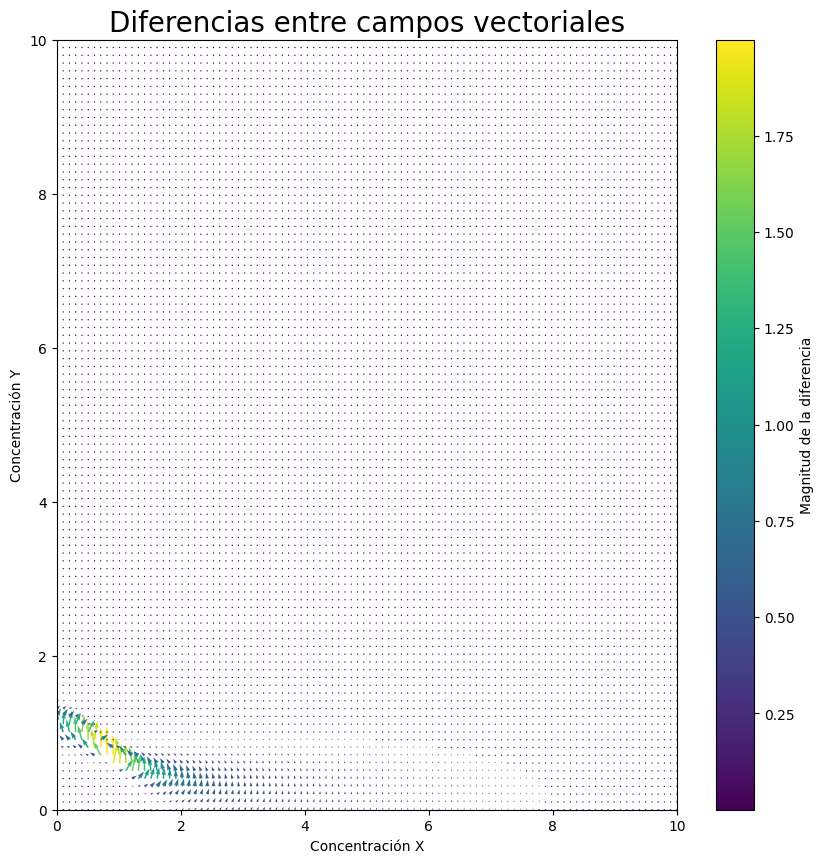

In [59]:
fig, ax = plt.subplots(figsize=(10, 10))

# Calculamos las diferencias
u_diff = u - upred
v_diff = v - vpred

# Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
epsilon = 1e-7
u_diff2 = u_diff + epsilon
v_diff2 = v_diff + epsilon

# Ahora calculamos la magnitud
#M_diff = np.hypot(u_diff2, v_diff2)
M_diff = np.hypot(u_diff, v_diff)

#Calcula la magnitud de los vectores
magnitudes = np.sqrt(u_diff**2 + v_diff**2)

# Calcula el rango de las magnitudes
rango = (np.max(magnitudes) - np.min(magnitudes))*30
print(rango)
# Escala para las flechas. Aumenta este valor si las flechas son demasiado grandes.
scale = 70

# Graficamos las diferencias
#Q = ax.quiver(Y1, Y2, u_diff2, v_diff2, M_diff, angles='xy')
Q = ax.quiver(Y1, Y2, u_diff, v_diff, M_diff, angles='xy', scale = rango)
#Q = ax.quiver(Y1, Y2, u_diff, v_diff, M_diff, angles='xy')


ax.set_title('Diferencias entre campos vectoriales', fontsize=20)
ax.set_xlim([0, 10])
ax.set_ylim([0, 10])
ax.set_xlabel('Concentración X')
ax.set_ylabel('Concentración Y')

# Creamos una leyenda para la magnitud de las flechas
cbar = plt.colorbar(Q, ax=ax)
cbar.set_label('Magnitud de la diferencia')

plt.show()

In [60]:
M_diff.mean()

0.04049698163316182

## Errores relativos

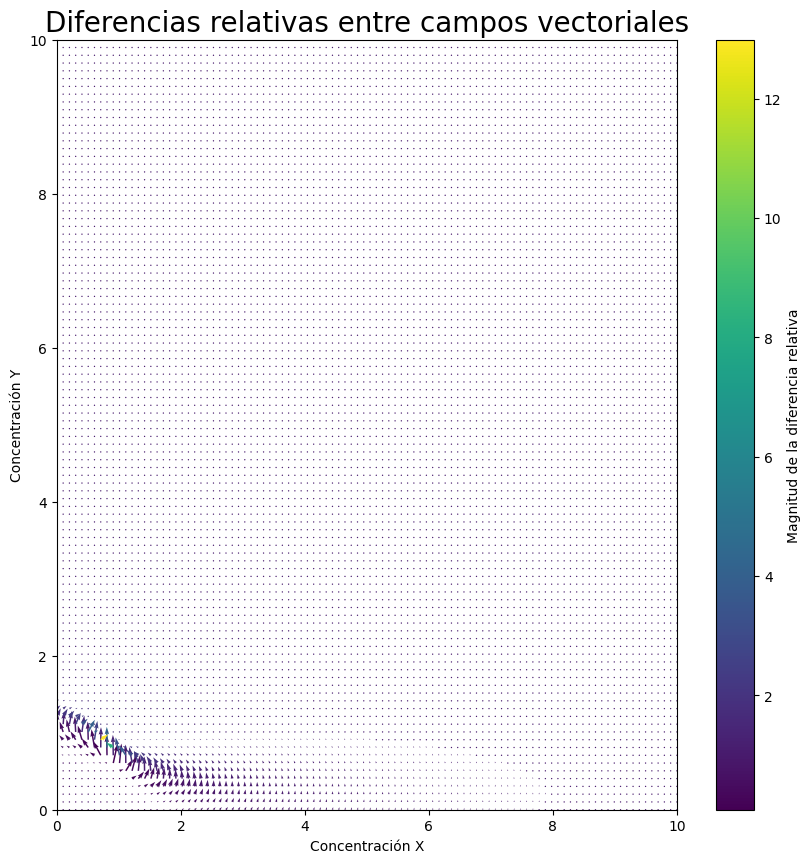

In [61]:
fig, ax = plt.subplots(figsize=(10, 10))

# Calculamos las diferencias
u_diff = u - upred
v_diff = v - vpred

# Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
epsilon = 1e-7

# Calculamos la magnitud del vector original y de la diferencia
M_orig = np.hypot(u1, v1) + epsilon
M_diff = np.hypot(u1pred, v1pred)

# Calculamos la diferencia relativa
M_diff_rel = M_diff / M_orig

#Calcula la magnitud de los vectores
magnitudes = np.sqrt(u_diff**2 + v_diff**2)

# Calcula el rango de las magnitudes
rango = (np.max(magnitudes) - np.min(magnitudes))*30

# Graficamos las diferencias relativas
Q = ax.quiver(Y1, Y2, u_diff, v_diff, M_diff_rel, angles='xy', scale = rango)

ax.set_title('Diferencias relativas entre campos vectoriales', fontsize=20)
ax.set_xlim([0, 10])
ax.set_ylim([0, 10])
ax.set_xlabel('Concentración X')
ax.set_ylabel('Concentración Y')

# Creamos una leyenda para la magnitud de las flechas
cbar = plt.colorbar(Q, ax=ax)
cbar.set_label('Magnitud de la diferencia relativa')

plt.show()

In [62]:
max_index_flattened = M_diff_rel.argmax()
max_coords = np.unravel_index(max_index_flattened, M_diff_rel.shape)
M_orig[max_coords]
print('El valor máximo de error relativo es de:', M_diff_rel.max() )
print('El valor de u1 en el error relativo máximo es:',u1[max_coords])
print('El valor de u1pred en el error relativo máximo es:',u1pred[max_coords])
print('El valor de v1 en el error relativo máximo es:',v1[max_coords])
print('El valor de v1pred en el error relativo máximo es:',v1pred[max_coords])

El valor máximo de error relativo es de: 12.98862026856812
El valor de u1 en el error relativo máximo es: 0.13336989807578048
El valor de u1pred en el error relativo máximo es: 0.13336989807578048
El valor de v1 en el error relativo máximo es: -0.09070502315859663
El valor de v1pred en el error relativo máximo es: -2.0907050231585966


In [63]:
np.sqrt(u1pred[max_coords]**2+v1pred[max_coords]**2)/np.sqrt(u1[max_coords]**2+v1[max_coords]**2)

12.988628321456538

In [64]:
# Calculamos las diferencias
u_diff = u - upred
v_diff = v - vpred

# Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
epsilon = 1e-7

# Calculamos la magnitud del vector original y de la diferencia
M_orig = np.hypot(u, v) + epsilon
M_diff = np.hypot(u_diff, v_diff)

# Calculamos la diferencia relativa
M_diff_rel = M_diff / M_orig

# Aplicamos el filtro para la diferencia relativa mayor a 0.05
mask = M_diff_rel > 0.05

# Calculamos el porcentaje de puntos que cumplen con la condición
porcentaje = np.mean(mask) * 100

print(f"El porcentaje de puntos cuyo error relativo es mayor a 0.05 es {porcentaje:.2f}%")

El porcentaje de puntos cuyo error relativo es mayor a 0.05 es 17.88%


## Simulamos n veces

In [65]:
import numpy as np
import random
from scipy.optimize import fsolve

# Listas para almacenar los resultados
porcentajes = []

# Repetimos el proceso 10 veces
for repetir in range(10000):
    campvec = []
    coef = []
    # constantes
    a1 = random.randint(0, 10)
    a2 = random.randint(0, 10)
    b1 = random.randint(0, 10)
    b2 = random.randint(0, 10)
    d1 = random.randint(0, 10)
    d2 = random.randint(0, 10)
    n = random.randint(0, 5)

    coef1 = [a1, a2, b1, b2, d1, d2, n]
    coef.append(coef1)

    def f(t, y):

        # asignar a cada ODE a un elemento de vector
        X = y[0]
        Y = y[1]

        # definimos cada ODE
        dX_dt = a1/(1+Y**n)-d1*X+b1
        dY_dt = a2/(1+X**n)-d2*Y+b2

        return [dX_dt, dY_dt]

    x_range_neg = 0
    x_range_pos = 10
    y_range_neg = 0
    y_range_pos = 10

    y1 = np.linspace(x_range_neg, x_range_pos, 100)
    y2 = np.linspace(y_range_neg, y_range_pos, 100)

    Y1, Y2 = np.meshgrid(y1, y2)
    
    t1 = 0

    u, v = np.zeros(Y1.shape), np.zeros(Y2.shape)

    NI, NJ = Y1.shape

    u1, v1 = f(t1, [Y1, Y2])
    u, v = f(t1, [Y1, Y2])
    M = (np.hypot(u, v))
    u /= M
    v /= M

    campvecci = np.append([u1], [v1], axis=0)

    campvec = campvecci
    print('--------------------------------------------')
#    print(coef1)
    
    campvec = np.array(campvec)

    
    campvecnone = campvec[None, :]
    campvecnone = np.transpose(campvecnone, (0,2,3,1))
    
    new_predictions = new_model.predict(campvecnone)
    new_predictions = np.round(new_predictions)
    new_predictions = np.clip(new_predictions, 0, None)
#    print(new_predictions)
    
    
    a1pred = new_predictions[0,0]
    a2pred = new_predictions[0,1]
    b1pred = new_predictions[0,2]
    b2pred = new_predictions[0,3]
    d1pred = new_predictions[0,4]
    d2pred = new_predictions[0,5]
    npred = new_predictions[0,6]
    
    def f(t, y):

        # asignar a cada ODE a un elemento de vector
        X = y[0]
        Y = y[1]

        # definimos cada ODE
        dX_dt = a1pred/(1+Y**npred)-d1pred*X+b1pred
        dY_dt = a2pred/(1+X**npred)-d2pred*Y+b2pred

        return [dX_dt, dY_dt]

    x_range_neg = 0
    x_range_pos = 10
    y_range_neg = 0
    y_range_pos = 10

    y1pred = np.linspace(x_range_neg, x_range_pos, 100)
    y2pred = np.linspace(y_range_neg, y_range_pos, 100)

    Y1pred, Y2pred = np.meshgrid(y1pred, y2pred)
    
    t1 = 0

    upred, vpred = np.zeros(Y1pred.shape), np.zeros(Y2pred.shape)

    NI, NJ = Y1.shape

    u1pred, v1pred = f(t1, [Y1, Y2])
    upred, vpred = f(t1, [Y1, Y2])
    Mpred = (np.hypot(upred, vpred))
    upred /= Mpred
    vpred /= Mpred

 # Calculamos las diferencias
    u_diff = u - upred
    v_diff = v - vpred

    # Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
    epsilon = 1e-7

    # Calculamos la magnitud del vector original y de la diferencia
    M_orig = np.hypot(u, v) + epsilon
    M_diff = np.hypot(u_diff, v_diff)

    # Calculamos la diferencia relativa
    M_diff_rel = M_diff / M_orig

    # Aplicamos el filtro para la diferencia relativa mayor a 0.05
    mask = M_diff_rel > 0.05

    # Calculamos el porcentaje de puntos que cumplen con la condición
    porcentaje = np.mean(mask) * 100

    # Almacenamos el resultado en la lista
    porcentajes.append(porcentaje)

    print(f"El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración {repetir+1} es {porcentaje:.2f}%")

# Muestra todos los porcentajes al final
print("Porcentajes para las 10 iteraciones:", porcentajes)

# Calcula y muestra el promedio de los porcentajes
promedio = np.mean(porcentajes)
print(f"El promedio de los porcentajes es {promedio:.2f}%")


--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 1 es 1.59%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 2 es 2.04%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 3 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 4 es 15.47%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 5 es 0.00%
--------------------------------------------
1/1 [=============================

1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 89 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 90 es 6.44%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 91 es 2.61%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 92 es 3.78%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 93 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos

1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 177 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 178 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 179 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 14ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 180 es 2.41%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 181 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de p

1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 265 es 13.46%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 266 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 267 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 268 es 1.35%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 269 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de 

1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 353 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 354 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 355 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 356 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 357 es 15.60%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de 

1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 441 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 442 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 443 es 9.36%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 444 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 445 es 4.74%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de p

... (208 outputs left out)

1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9831 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9832 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9833 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9834 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9835 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje

1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9875 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9876 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 14ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9877 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 14ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9878 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9879 es 8.44%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje

1/1 [==============================] - 0s 15ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9919 es 11.69%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9920 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9921 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 15ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9922 es 11.27%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9923 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcenta

El promedio de los porcentajes es 4.72%


El promedio de los porcentajes es 4.72%


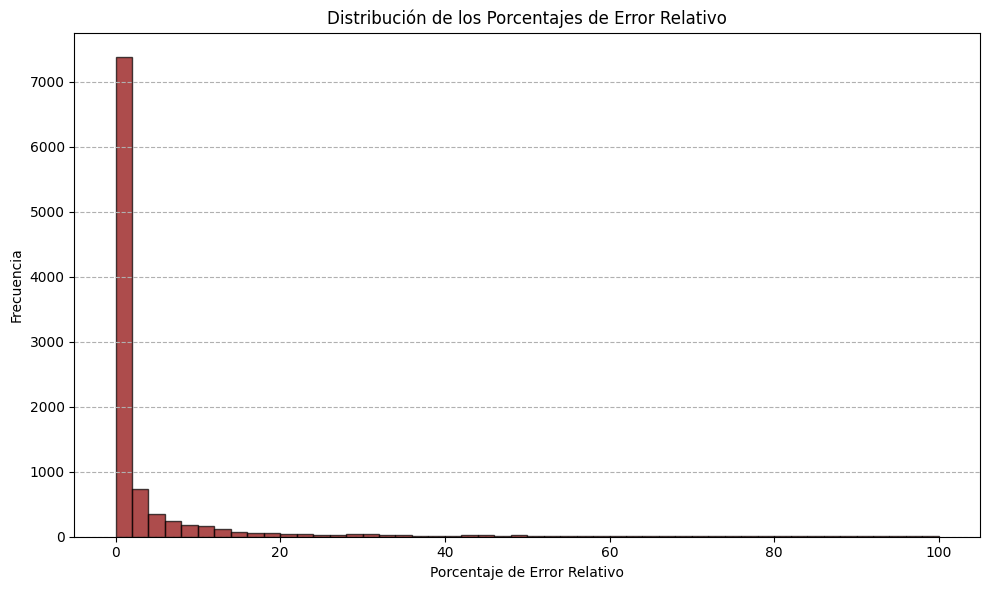

In [67]:
import matplotlib.pyplot as plt

# Calcula y muestra el promedio de los porcentajes
promedio = np.mean(porcentajes)
print(f"El promedio de los porcentajes es {promedio:.2f}%")

# Crea un histograma de los porcentajes
plt.figure(figsize=(10, 6))
plt.hist(porcentajes, bins=50, edgecolor='black', alpha=0.7, color = 'darkred')
plt.title('Distribución de los Porcentajes de Error Relativo')
plt.xlabel('Porcentaje de Error Relativo')
plt.ylabel('Frecuencia')
plt.grid(axis='y', linestyle='--')
plt.tight_layout()
plt.show()